# Gridworld: sampled episodes, exact values, and policy gradients

A fixed policy turns the finite-horizon MDP in `gridworld/model.py` into trajectories.
We will inspect action probabilities, draw one complete episode, and separate
policy sampling, environmental slip, and reward noise. Then we will compute
exact values by averaging over every possible outcome under the same fixed
policy, read spatial value/probability/advantage maps, and differentiate its
expected return with respect to the logits. Finally,
we will estimate that gradient from complete episodes with full-return REINFORCE
and reward-to-go, then subtract a fixed state baseline.
We fit a state baseline on separate data, then measure bias, variance, and MSE
across repeated independent batches, then compare reward noise and episode counts.
Then we replace sampled future rewards with a one-step TD bootstrap and
isolate the bias from an imperfect critic. The policy stays fixed;
there are no policy updates.

From `rl_math`, run `uv sync --locked` and then
`uv run --locked jupyter lab notebooks/01_gridworld.ipynb`. The project
environment includes NumPy, Matplotlib, JupyterLab, and its Python kernel.
PyTorch handles differentiable probability/value calculations; NumPy owns the seeded random draws. Run
the cells in order from the repository root, `rl_math`, or this notebook's directory.

This notebook explicitly uses CUDA. The setup cell prints the GPU name;
logits, probabilities, exact values, and autograd derivatives stay on that device.
The library also supports `device="cpu"` for reference checks.


In [1]:
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import torch
import platform
import sys

project = next(p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "rl_math")
               if (p / "gridworld" / "model.py").is_file())
sys.path.insert(0, str(project))
from gridworld.model import Action, Gridworld, State
from common.returns import discounted_returns
from common.policy import Policy
from gridworld.policy import TabularSoftmaxPolicy
from gridworld.sampling import sample_episode
from gridworld.values import evaluate_policy
from gridworld.gradients import differentiate_policy
from gridworld.figures import FIGURE_SEEDS, POLICY_NAME, safe_route_policy
from gridworld.plotting import plot_advantages, plot_policy_values, plot_trajectories
from algorithms.reinforce import full_return_gradient

print("Python", platform.python_version(), "NumPy", np.__version__, "PyTorch", torch.__version__, "Matplotlib", matplotlib.__version__)

device = torch.device("cuda")
assert torch.cuda.is_available(), "CUDA is unavailable; check the NVIDIA driver and PyTorch environment."
print("Device:", device, "GPU:", torch.cuda.get_device_name(0))


Python 3.10.12 NumPy 2.2.6 PyTorch 2.14.1+cu130 Matplotlib 3.10.9
Device: cuda GPU: NVIDIA GeForce RTX 3090


## The policy interface

`common/policy.py` defines `Policy[Observation]`, an abstract interface for
discrete-action policies. Its required method, `probabilities(observation)`,
returns a normalized PyTorch tensor in the environment's action order.
The tensor retains the computation graph when its probabilities depend on parameters.
The observation type can be a gridworld state or another representation,
such as a vector. `gridworld/policy.py` supplies
`TabularSoftmaxPolicy(Policy[State])`, the gridworld implementation. A rule-based policy can implement the same
method without having logits at all.

`gridworld.sampling.sample_episode` accepts `Policy[State]` and owns the random draws. It
detaches the probability tensor before passing it to NumPy's random generator.
It does not inspect the concrete policy's parameters. This keeps environment
sampling separate from how the policy represents action probabilities
and from the algorithm that may later update its parameters.

`log_probabilities(observation)` retains the same graph for score derivatives.
The default takes the log of the probabilities; the tabular policy overrides
it with `torch.log_softmax` to avoid underflow when logits are far apart.


## One row of a tabular policy

For the full state $s=(\mathrm{cell},\mathrm{remaining})$, assign four logits
$\theta_{s,a}$ in **north, east, south, west** order:

$$\pi_\theta(a\mid s)=\frac{\exp(\theta_{s,a})}{\sum_b\exp(\theta_{s,b})}.$$

The row $(\log 1,\log 2,\log 3,\log 4)$ gives probabilities
$(0.1,0.2,0.3,0.4)$. `probabilities` uses `torch.softmax`, which evaluates the ratios stably and
records their derivatives. Each logit row is an owned float64 CUDA
`torch.nn.Parameter`; changing the caller's original array/tensor leaves it unchanged.


In [2]:
world = Gridworld()  # Default 5x5 map; horizon=12, slip=0.2.
example = TabularSoftmaxPolicy({world.start_state: torch.tensor([1., 2., 3., 4.], dtype=torch.float64).log()}, device=device)
for action, probability in zip(Action, example.probabilities(world.start_state)):
    print(f"{action.name:5s}: {probability:.1f}")
assert torch.isclose(example.probabilities(world.start_state).sum(), example.probabilities(world.start_state).new_tensor(1.))


NORTH: 0.1
EAST : 0.2
SOUTH: 0.3
WEST : 0.4


## A fixed preference for the longer safe route

The bottom row is `SHHHG`. Going north, east four times, then south avoids
the hazards when all moves succeed. Give the preferred action logit $\log 7$
and every other action logit $0$: the policy samples its preference with
probability $0.7$ and each other action with probability $0.1$.

This is a manually specified policy. Every nonterminal cell/time pair has its
own row, although we use the same preference at a cell for each remaining time.
The policy may choose another action, and slip may change where that action
lands. Even the preferred action does not guarantee a safe trajectory.

A **tabular** policy stores separate parameters for each state rather than
sharing them through a neural network. It can learn when an optimizer
updates those logits. Here they are chosen by hand and held fixed:
collecting episodes only generates data. The gridworld experiments first
hold the policy fixed to compare gradient estimators with an exact reference;
the later CartPole experiments add learning updates.


In [3]:
# Shared with the noninteractive figure command; inspect gridworld/figures.py.
# log(7) for the preferred action and 0 for each other action gives 0.7/0.1/0.1/0.1.
policy = safe_route_policy(world, device=device)
print("Start probabilities:", policy.probabilities(world.start_state).detach().cpu().numpy().round(2))

Start probabilities: [0.7 0.1 0.1 0.1]


## Draw and inspect a complete episode

At each time $t$, `sample_episode` makes three draws:

$$a_t\sim\pi_\theta(\cdot\mid s_t),\qquad
s_{t+1}\sim P(\cdot\mid s_t,a_t),\qquad
r_{t+1}=\bar r(s_t,a_t,s_{t+1})+\epsilon_{t+1},$$

where $\epsilon_{t+1}\sim\mathcal N(0,\sigma^2)$ independently at each step.
Here $\bar r$ is the selected transition's conditional expected reward;
`world.expected_reward(s, a)` additionally averages over possible next states.

Use seed **7**, slip **0.2**, horizon **12**, and reward-noise standard deviation
**2.0** for this illustration. NumPy `SeedSequence(seed).spawn(3)` creates separate
streams for actions, transitions, and reward noise; each uses `default_rng`.
The sampler leaves global random state alone. Repeating a seed replays an episode.
Use distinct nonnegative integer seeds for new samples, and keep the Python/NumPy
environment and all settings fixed when reproducing a run.
See [NumPy's stream-spawning explanation](https://numpy.org/doc/stable/reference/random/parallel.html).


In [4]:
seed, noise_std, gamma = 7, 2.0, 0.9
episode = sample_episode(world, policy, seed=seed, reward_noise_std=noise_std)
assert episode == sample_episode(world, policy, seed=seed, reward_noise_std=noise_std)
print(f"seed={episode.seed}, sigma={episode.reward_noise_std}, horizon={world.horizon}, slip={world.slip}")
print(" t   cell  left action  reward -> next cell left   end")
for step in episode.steps:
    print(f"{step.t:2d} {str(step.state.cell):>7} {step.state.remaining:4d} {step.action.name:5s} "
          f"{step.reward:7.3f} -> {str(step.next_state.cell):>7} "
          f"{step.next_state.remaining:4d} {str(step.terminated):>5}")
print("Ending:", episode.end_reason)
print(f"G_0 (gamma={gamma}) = {discounted_returns(episode.rewards(), gamma)[0]:.3f}")


seed=7, sigma=2.0, horizon=12, slip=0.2
 t   cell  left action  reward -> next cell left   end
 0  (4, 0)   12 EAST   -5.921 ->  (4, 1)   11 False
 1  (4, 1)   11 NORTH   1.216 ->  (3, 1)   10 False
 2  (3, 1)   10 EAST   -2.025 ->  (3, 2)    9 False
 3  (3, 2)    9 SOUTH  -4.254 ->  (4, 2)    8 False
 4  (4, 2)    8 EAST   -5.756 ->  (4, 3)    7 False
 5  (4, 3)    7 NORTH   1.383 ->  (3, 3)    6 False
 6  (3, 3)    6 NORTH  -1.627 ->  (2, 3)    5 False
 7  (2, 3)    5 EAST   -2.542 ->  (3, 3)    4 False
 8  (3, 3)    4 NORTH  -0.418 ->  (2, 3)    3 False
 9  (2, 3)    3 EAST   -0.367 ->  (2, 4)    2 False
10  (2, 4)    2 SOUTH  -2.187 ->  (2, 4)    1 False
11  (2, 4)    1 SOUTH  -1.517 ->  (3, 4)    0  True
Ending: horizon
G_0 (gamma=0.9) = -16.169


In [5]:
# Mark all visited cells; the table above gives their order and revisits.
visited = {step.state.cell for step in episode.steps} | {episode.steps[-1].next_state.cell}
for row, line in enumerate(world.layout):
    print(" ".join(symbol + ("*" if (row, column) in visited else " ")
                   for column, symbol in enumerate(line)))
print("* visited; S start, G goal, H hazard, # wall")


.  .  .  .  . 
.  .  #  .  . 
.  .  #  .* .*
.  .* .* .* .*
S* H* H* H* G 
* visited; S start, G goal, H hazard, # wall


In the NumPy seed-7 run, the policy samples EAST at t=0 even though NORTH
has higher probability; this sends it onto a hazard. At t=7 it selects
EAST from (2, 3) but moves SOUTH to (3, 3): that is environmental slip.
The episode ends at the horizon before reaching the goal.

The recorded `t` starts at zero for each episode; it is the exponent in the
outer $\gamma^t$ policy-gradient weight introduced in `common/returns.py`. Every
actual move decreases remaining time by one, including a move blocked by a wall.

The final transition is marked `terminated=True`: reaching the goal or
exhausting this task's horizon gives zero future value. There is no absorbing
tail, rollout cutoff, or external time-limit truncation in this sampler.
Reaching the goal on the last allowed move still pays the goal reward.


### Read three complete paths on the grid

Use the fixed seed list **0, 1, 7**, including the seed-7 episode above, with the
same policy and independent reward-noise standard deviation **2.0**. These are
illustrative paths, not a success-rate estimate or a selection of the best runs.
The blue path follows the **observed next cell**, after slip. Numbers mark visit
times, so stays and revisits remain visible even where lines overlap. The outlined
endpoint is either the goal or the cell reached when time expires.

Each panel starts with 12 steps remaining; at visit time $t$, the full state is
$(\mathrm{cell},12-t)$. A plot of policy arrows later in the notebook has a
different meaning: it describes intended actions before slip.

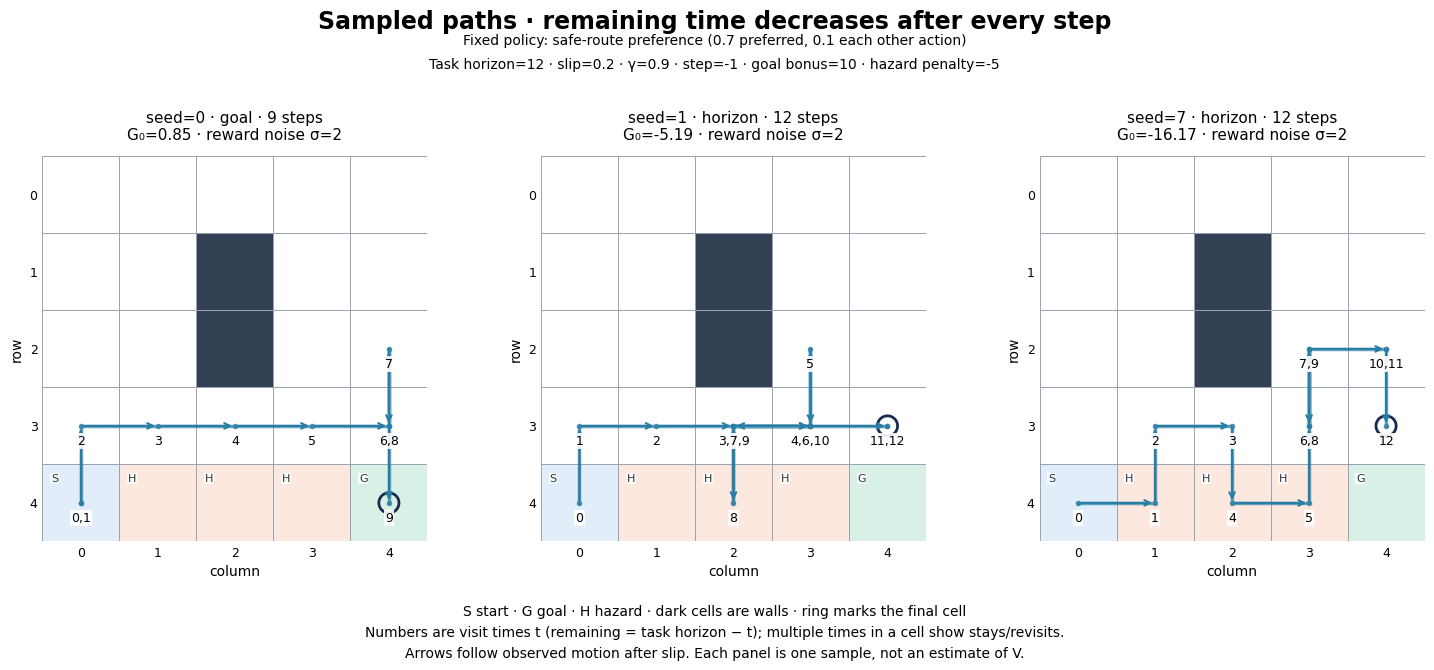

In [6]:
figure_episodes = [sample_episode(world, policy, seed=s, reward_noise_std=noise_std)
                   for s in FIGURE_SEEDS]
assert figure_episodes[-1] == episode
fig = plot_trajectories(world, figure_episodes, gamma=gamma, policy_name=POLICY_NAME)
display(fig)
plt.close(fig)

## Why noise changes variance, not the expected reward

The logits change action probabilities and thus which states are visited.
The environment supplies slip and reward noise. With this fixed state-only
policy, reward noise does not influence future actions or transitions.

Independence and zero mean give

$$\mathbb E[r_{t+1}\mid s_t,a_t,s_{t+1}]=\bar r(s_t,a_t,s_{t+1}),$$

so averaging over next states also preserves `world.expected_reward(s, a)`.
The added conditional reward variance is $\sigma^2$. Given a state/action path
of length $T$, the noise contribution to its discounted return has mean zero
and variance

$$\operatorname{Var}\!\left[\sum_{t=0}^{T-1}\gamma^t\epsilon_{t+1}\;\middle|\;
\mathrm{path}\right]=\sigma^2\sum_{t=0}^{T-1}\gamma^{2t}.$$

Unconditionally, expected return is also unchanged; the added return variance
averages this expression over paths. A particular noisy episode can have a
higher or lower return. It need not average to zero within that episode.

Changing only the noise scale keeps the same sampled path because its random
stream is separate. Compare the clean and noisy rewards on that path below.


In [7]:
clean = sample_episode(world, policy, seed=seed)
assert [(s.state, s.action, s.next_state) for s in clean.steps] == [
    (s.state, s.action, s.next_state) for s in episode.steps]
print(" t model reward   noise observed reward")
for base, noisy in zip(clean.steps, episode.steps):
    print(f"{base.t:2d} {base.reward:12.3f} {noisy.reward - base.reward:7.3f} {noisy.reward:15.3f}")
times = np.arange(len(episode.steps))
variance = noise_std**2 * np.sum(gamma**(2 * times))
print(f"Added return variance conditional on this path: {variance:.3f}")


 t model reward   noise observed reward
 0       -6.000   0.079          -5.921
 1       -1.000   2.216           1.216
 2       -1.000  -1.025          -2.025
 3       -6.000   1.746          -4.254
 4       -6.000   0.244          -5.756
 5       -1.000   2.383           1.383
 6       -1.000  -0.627          -1.627
 7       -1.000  -1.542          -2.542
 8       -1.000   0.582          -0.418
 9       -1.000   0.633          -0.367
10       -1.000  -1.187          -2.187
11       -1.000  -0.517          -1.517
Added return variance conditional on this path: 19.373


## Exact values by backward dynamic programming

A sampled $G_t$ is one return. The value $V^\pi(s)$ is its expectation under
the fixed policy. Since $s$ contains remaining time, the tables depend on both
cell and time; discounting starts at the state being evaluated:

$$Q^\pi(s,a)=\sum_{s'}P(s'\mid s,a)
  [\bar r(s,a,s')+\gamma V^\pi(s')],\qquad
V^\pi(s)=\sum_a\pi(a\mid s)Q^\pi(s,a),\qquad
A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s).$$

`gridworld.values.evaluate_policy` starts with zero values at the goal and at
remaining time zero, then computes rows with 1, 2, ..., horizon steps left.
Every nonterminal successor has one fewer step left, so its value is already
available. The code's `torch.dot(probabilities, rewards + gamma * future_values)`
averages over model outcomes; `torch.dot(policy.probabilities(state), q[state])`
averages over actions. No samples or convergence loop are needed, even at
$\gamma=1$. All non-wall cell/time pairs are evaluated, including unreachable ones.

V, Q, advantage, and J are float64 tensors. `torch.stack` combines successor
values while retaining their graph; converting them to Python floats, NumPy,
or `torch.tensor(list_of_values)` inside this recurrence would break that path.
Fixed transition probabilities and mean rewards are constant tensors. We detach
only for display/sampling, and use `.item()` when a scalar is needed for a check.

For our deterministic start, $J(\theta)=V^{\pi_\theta}(s_0)$.
Independent zero-mean reward noise leaves this expectation unchanged.

### A two-step calculation you can check by hand

Use the one-row map `SHG`, no slip, horizon 2, $\gamma=0.5$, and
$\pi=(0.1,0.2,0.3,0.4)$ in north/east/south/west order at every nonterminal
state. An ordinary step pays $-1$, entering or staying on H pays $-6$, and
entering G pays $9$. Start with zero terminal values.

With one step left, $V(S,1)=0.8(-1)+0.2(-6)=-2$ and
$V(H,1)=0.4(-6)+0.2(9)+0.4(-1)=-1$.
With two steps left, an EAST action at S has
$Q(S,2,\mathrm{E})=-6+0.5V(H,1)=-6.5$;
the other actions stay at S, giving $-1+0.5V(S,1)=-2$.
Thus $J=V(S,2)=0.8(-2)+0.2(-6.5)=-2.9$.
The computed table below includes Q and advantage in the same action order.

In [8]:
tiny = Gridworld(layout=("SHG",), horizon=2, slip=0)
tiny_policy = TabularSoftmaxPolicy({
    s: torch.tensor([1., 2., 3., 4.], dtype=torch.float64).log() for s in tiny.states() if not tiny.is_terminal(s)
}, device=device)
tiny_values = evaluate_policy(tiny, tiny_policy, gamma=0.5)
print("cell left | Q(N,E,S,W)               | V     | A(N,E,S,W)")
for remaining in (1, 2):
    for cell, label in ((tiny.start, "S"), ((0, 1), "H")):
        state = State(cell, remaining)
        print(f"{label:>4} {remaining:4d} | {str(tiny_values.q[state].detach().cpu().numpy().round(2)):24s} | "
              f"{tiny_values.v[state]:5.2f} | {tiny_values.advantage[state].detach().cpu().numpy().round(2)}")
assert np.isclose(tiny_values.start_return.item(), -2.9)
assert all(tiny_values.v[s] == 0 for s in tiny.states() if tiny.is_terminal(s))
print(f"J = V(S,2) = {tiny_values.start_return:.2f}; all terminal V/Q/A rows are zero.")

cell left | Q(N,E,S,W)               | V     | A(N,E,S,W)
   S    1 | [-1. -6. -1. -1.]        | -2.00 | [ 1. -4.  1.  1.]
   H    1 | [-6.  9. -6. -1.]        | -1.00 | [-5. 10. -5.  0.]
   S    2 | [-2.  -6.5 -2.  -2. ]    | -2.90 | [ 0.9 -3.6  0.9  0.9]
   H    2 | [-6.5  9.  -6.5 -2. ]    | -1.60 | [-4.9 10.6 -4.9 -0.4]
J = V(S,2) = -2.90; all terminal V/Q/A rows are zero.


The policy-weighted advantage is zero because

$$\sum_a\pi(a\mid s)A^\pi(s,a)
=\sum_a\pi(a\mid s)Q^\pi(s,a)-V^\pi(s)\sum_a\pi(a\mid s)
=V^\pi(s)-V^\pi(s)=0.$$

At $(S,2)$, this is $0.8(0.9)+0.2(-3.6)=0$. The **unweighted** average
need not vanish. Positive advantage means better than the policy's average
choice at that state, even when Q itself is negative.

Replacing the policy average over next actions with a maximum chooses the
best continuation instead of following $\pi$. Applied throughout the backward
pass, that gives the Bellman optimality equation and a different policy's
return. Here even the current row's maximum Q, $-2$, differs from its
policy-weighted value, $-2.9$. We keep the policy fixed.

### Evaluate the earlier 5×5 policy

Now use the same manually chosen safe-route preferences, slip 0.2, horizon 12,
and $\gamma=0.9$ as the sampled episode. Each printed map fixes remaining time.
G has value zero because its entry reward was paid on the preceding transition;
the horizon-zero slice is also entirely zero. These are exact model
expectations, so a single noisy trajectory need not have return near J.

In [9]:
values = evaluate_policy(world, policy, gamma=gamma)
print(f"Expected start return J (gamma={gamma}): {values.start_return:.6f}")
for remaining in (1, world.horizon):
    print(f"\nV with {remaining} step(s) left:")
    for row, line in enumerate(world.layout):
        print(" ".join("    #  " if symbol == "#" else
                       f"{values.v[State((row, column), remaining)]:7.2f}"
                       for column, symbol in enumerate(line)))

nonterminal = [s for s in world.states() if not world.is_terminal(s)]
residual = max(abs(torch.dot(policy.probabilities(s), values.advantage[s]).item())
               for s in nonterminal)
assert residual < 1e-12
print(f"\nMax |sum_a pi(a|s) A(s,a)| over nonterminal rows: {residual:.2e}")

Expected start return J (gamma=0.9): -8.556035

V with 1 step(s) left:
  -1.00   -1.00   -1.00   -1.00   -1.00
  -1.00   -1.00     #     -1.00   -1.00
  -1.00   -1.00     #     -1.00   -1.00
  -1.00   -1.70   -1.70   -1.70    4.80
  -1.70   -2.40   -3.10   -1.00    0.00

V with 12 step(s) left:
  -6.50   -5.87   -4.74   -3.43   -2.19
  -7.11   -7.02     #     -1.86   -0.34
  -7.26   -7.16     #      0.09    2.35
  -7.10   -6.32   -3.41    0.76    5.94
  -8.56   -8.71   -7.07   -1.71    0.00

Max |sum_a pi(a|s) A(s,a)| over nonterminal rows: 1.39e-15


### Read V and the policy at a fixed remaining horizon

Each map fixes the **full state's remaining time**, and includes every non-wall
cell, even cells that cannot be reached from the start at that time. Row 0 is at
the top; coordinates match `State((row, column), remaining)`. Compare one step
left with twelve: the policy's chosen probabilities are the same at both times,
but V changes because different future rewards can still be collected.

The right panel prints **all four action probabilities**. Arrow size increases
with probability; these arrows show intended actions, while environmental slip
can send the agent elsewhere. No action is taken at G or at remaining time zero.
The left panel labels exact $V^\pi(s)=\sum_a\pi(a\mid s)Q^\pi(s,a)$ to two decimals.
The V color scale is local to each figure; use printed values to compare horizons.
Plotting detaches tensors only when copying numbers to the display; Bellman and
policy computations stay on CUDA.

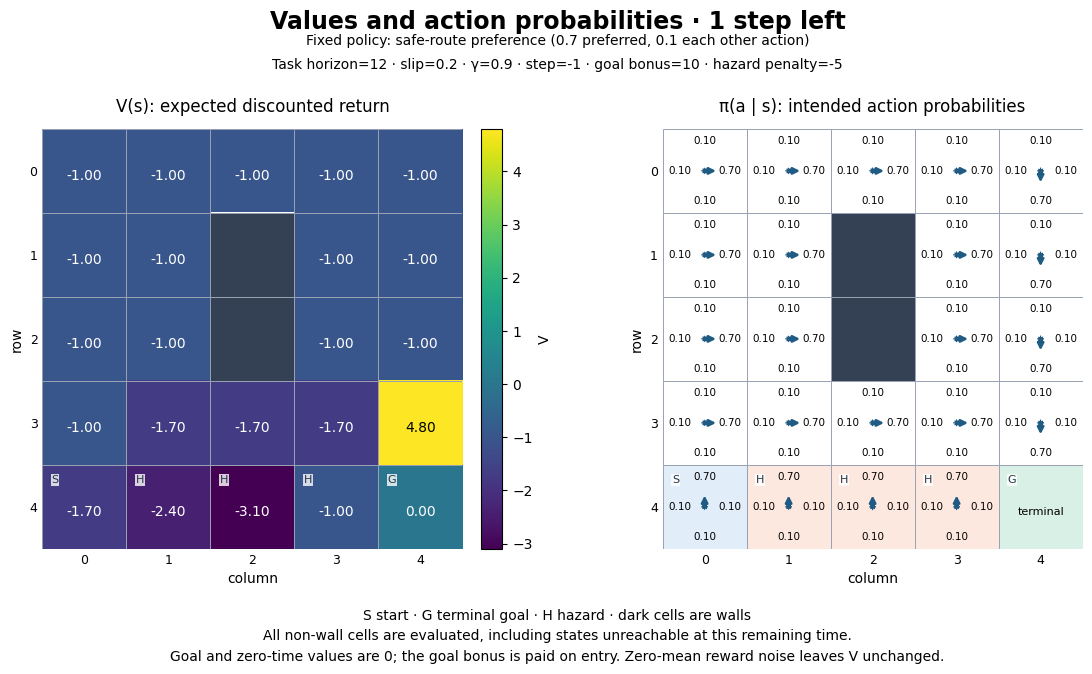

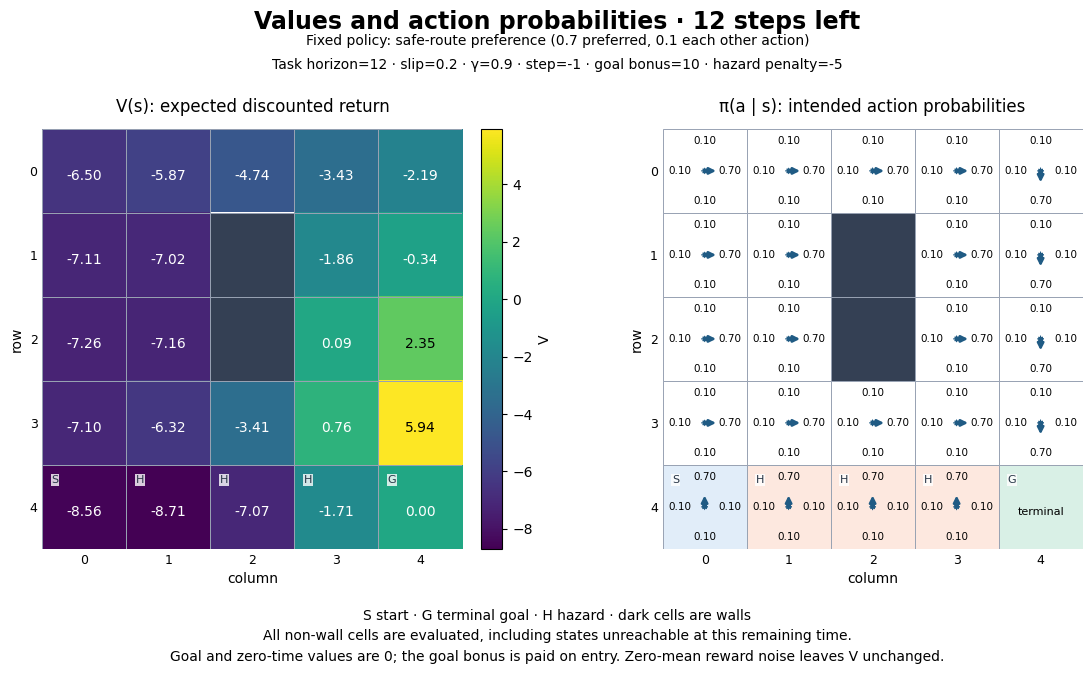

In [10]:
for remaining in (1, world.horizon):
    fig = plot_policy_values(world, policy, values, remaining=remaining,
                             gamma=gamma, policy_name=POLICY_NAME)
    display(fig)
    plt.close(fig)

### Action advantage is relative to the policy's average

The four panels share a symmetric scale centered at zero and use the exact
$A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s)$ table. Positive (blue) means better than this
policy's average at the **same cell and remaining time**, even when V and Q are
negative. It does not imply a positive return or a guaranteed good sampled outcome.
The values average over both policy actions and slip; independent zero-mean
reward noise leaves these expectations unchanged.

For the earlier two-step `SHG` example at $(S,2)$,
$V=-2.9$, $Q(\mathrm{NORTH})=-2$, and
$A(\mathrm{NORTH})=-2-(-2.9)=+0.9$. Thus **an action can have positive advantage
in a state with negative value**. EAST has $A=-3.6$, and the policy-weighted
average is $0.8(0.9)+0.2(-3.6)=0$; an unweighted average need not be zero.
The table below connects selected 5×5 map cells to their full-precision evaluator
rows. The plotted numbers are the same values rounded to two decimals.

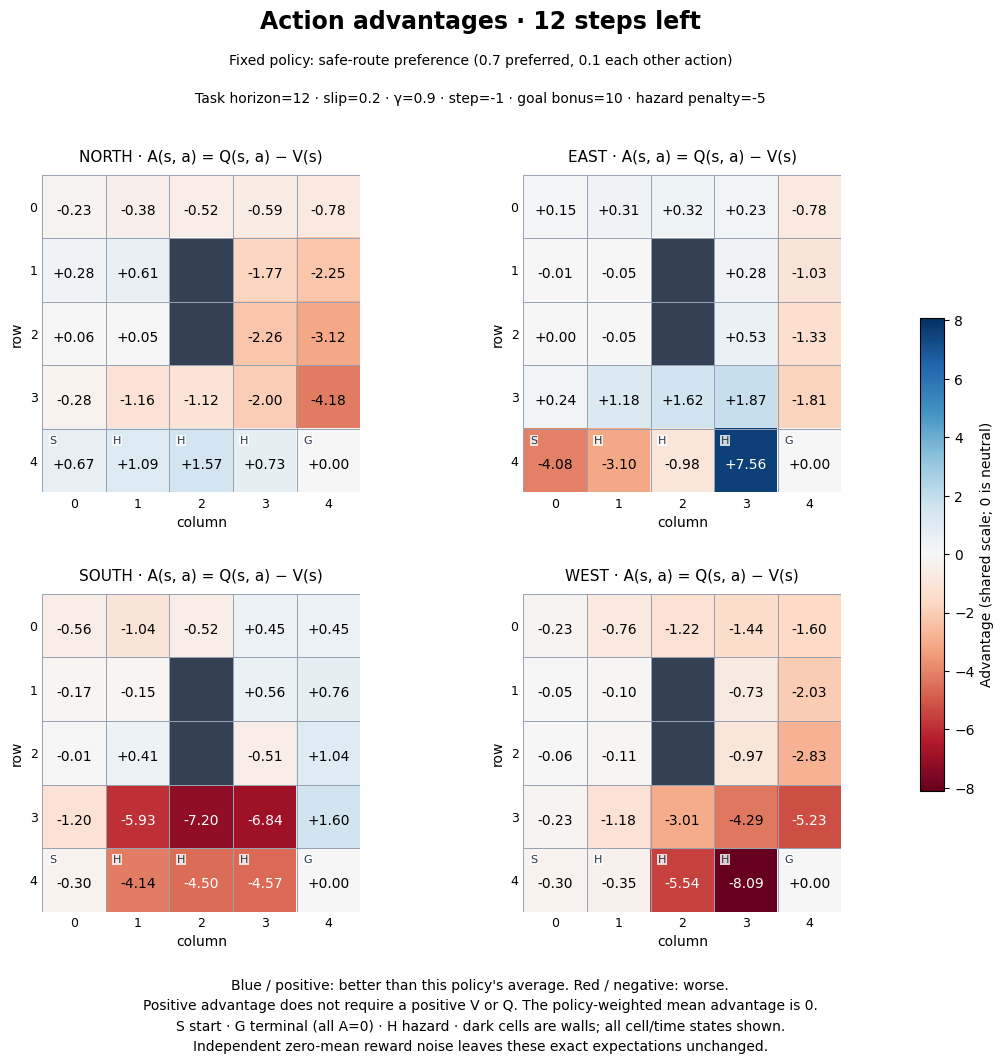

cell  left | V        | pi(N,E,S,W)       | Q(N,E,S,W)                    | A(N,E,S,W)
(4, 0)    1 |  -1.7000 | [0.7 0.1 0.1 0.1] | [-1.3333 -5.     -1.3333 -1.3333] | [ 0.3667 -3.3     0.3667  0.3667]
(4, 0)   12 |  -8.5560 | [0.7 0.1 0.1 0.1] | [ -7.8882 -12.6391  -8.8518  -8.8518] | [ 0.6678 -4.083  -0.2958 -0.2958]
(3, 3)   12 |   0.7619 | [0.1 0.7 0.1 0.1] | [-1.2347  2.6362 -6.0761 -3.5235] | [-1.9967  1.8743 -6.838  -4.2855]
SHG, S with 2 steps left: V=-2.9, Q(NORTH)=-2.0, A(NORTH)=+0.9.


In [11]:
fig = plot_advantages(world, values, remaining=world.horizon,
                      gamma=gamma, policy_name=POLICY_NAME)
display(fig)
plt.close(fig)
print("cell  left | V        | pi(N,E,S,W)       | Q(N,E,S,W)                    | A(N,E,S,W)")
for state in (State(world.start, 1), world.start_state, State((3, 3), world.horizon)):
    pi = policy.probabilities(state).detach().cpu().numpy()
    q = values.q[state].detach().cpu().numpy()
    a = values.advantage[state].detach().cpu().numpy()
    v = values.v[state].item()
    np.testing.assert_allclose(a, q - v, rtol=1e-12, atol=1e-12)
    assert abs(np.dot(pi, a)) < 1e-12
    print(f"{state.cell} {state.remaining:4d} | {v:8.4f} | {pi.round(2)} | {q.round(4)} | {a.round(4)}")
hand_state = State(tiny.start, 2)
assert tiny_values.v[hand_state].item() < 0 < tiny_values.advantage[hand_state][0].item()
print("SHG, S with 2 steps left: V=-2.9, Q(NORTH)=-2.0, A(NORTH)=+0.9.")

### Reproduce and save the selected figures

From `rl_math`, run the following without a notebook or browser:

```bash
uv sync --locked
uv run --locked python -m gridworld.figures --output-dir runs/gridworld-figures --device cuda
```

This uses the same model, fixed policy, $\gamma=0.9$, noise $\sigma=2$, and seed
list. It saves the paths, both value/policy slices, the horizon-12 advantage map,
and `manifest.json` with settings, versions, selected exact rows, sampled data,
and runtime. **Choose a new output directory for each run**; the command refuses
to overwrite an existing directory. Notebook display itself writes no figure
files. The committed examples are in `figures/gridworld/`. `--device cpu` is
available for the independent reference path; the notebook and default figure
command use CUDA. No training or policy update is involved.

## Differentiate the exact expected return with PyTorch

Knowing the model lets us differentiate $J(\theta)=V^{\pi_\theta}(s_0)$ itself.
The evaluator has already built the graph
**logits → softmax probabilities → Bellman expectations → J**.
`gridworld.gradients.differentiate_policy` evaluates J, then calls
[`torch.autograd.grad`](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html)
on it and all the logit parameters. PyTorch applies the chain rule through the
whole graph; we do not implement a separate backward algorithm.

`materialize_grads=True` returns zeros for rows disconnected from J, including
optional terminal rows. `autograd.grad` returns derivatives without accumulating
the parameters' `.grad` buffers or updating them. The returned `PolicyGradient`
contains `values` and `gradient`, a detached tensor for each supplied logit row.

For interpretation, the local softmax derivative is still

$$\frac{\partial\pi(a\mid s)}{\partial\theta_{s,b}}
=\pi(a\mid s)\bigl(\mathbf 1[a=b]-\pi(b\mid s)\bigr).$$

Combining this with the Bellman expectations gives

$$\frac{\partial J}{\partial\theta_{s,b}}
=\gamma^t\Pr(s_t=s)\,\pi(b\mid s)\,A(s,b),
\qquad t=H-\mathrm{remaining}.$$

Each cell/remaining-time row has independent parameters. The local Q/advantage
discounts rewards relative to that state; the outer $\gamma^t$ discounts back
to the episode start. Autograd obtains both from the same gamma factors in the
value computation, including dependencies through successor values. We do not
normalize by episode length or total occupancy.


### Continue the two-step `SHG` example

Keep $\gamma=0.5$, no slip, and $\pi=(0.1,0.2,0.3,0.4)$ in each row.
At $t=0$ we are at $(S,2)$ with weight 1. At $t=1$, the state is $(S,1)$
with probability 0.8 or $(H,1)$ with probability 0.2. Their reverse weights are
$0.5(0.8)=0.4$ and $0.5(0.2)=0.1$.

For example, the EAST derivative at the start is
$1(0.2)(-3.6)=-0.72$. At $(H,1)$ it is
$0.1(0.2)(10)=0.20$: the goal reward matters only on paths visiting that row,
and its effect on J is discounted once. The complete gradient rows are below.
$(H,2)$ has nonzero local action advantages but is unreachable from the start,
so all its derivatives of J are zero.


In [12]:
reference = differentiate_policy(tiny, tiny_policy, gamma=0.5)
assert reference.values.start_return.item() == tiny_values.start_return.item()
print(f"Exact J = {reference.values.start_return.item():.2f}")
print("cell left | dJ/dlogits (N,E,S,W)")
for cell, label, remaining in ((tiny.start, "S", 2), (tiny.start, "S", 1),
                               ((0, 1), "H", 1), ((0, 1), "H", 2)):
    state = State(cell, remaining)
    print(f"{label:>4} {remaining:4d} | {reference.gradient[state].cpu().numpy().round(4)}")
torch.testing.assert_close(reference.gradient[State((0, 1), 1)],
                           reference.gradient[State((0, 1), 1)].new_tensor([-.05, .2, -.15, 0]),
                           rtol=1e-12, atol=1e-14)


Exact J = -2.90
cell left | dJ/dlogits (N,E,S,W)
   S    2 | [ 0.09 -0.72  0.27  0.36]
   S    1 | [ 0.04 -0.32  0.12  0.16]
   H    1 | [-0.05  0.2  -0.15  0.  ]
   H    2 | [0. 0. 0. 0.]


### Check every logit with central finite differences

For a single parameter $\theta_{s,b}$, change only that entry and call the
previous value evaluator twice:

$$D_{s,b}(\epsilon)=\frac{J(\theta+\epsilon e_{s,b})
-J(\theta-\epsilon e_{s,b})}{2\epsilon}.$$

This check differentiates the scalar return numerically without using the
autograd result. Use $\epsilon=10^{-5}$ in float64, with absolute tolerance
$10^{-8}$ plus relative tolerance $10^{-6}$ (`torch.testing.assert_close`).
The absolute term covers derivatives near zero. Central differences have
$O(\epsilon^2)$ truncation error for this smooth objective; very small steps can
instead magnify floating-point cancellation. These settings apply to this tiny,
moderately scaled example, rather than every possible logit/reward scale.

We perturb all 16 independent logits, including unreachable rows, in the `SHG`
model. Its step costs and hazard penalties give nontrivial rewards before the
last transition. Omitting the outer discount would double the nonzero $t=1$
derivatives and fail this check. Detach and clone each row to leave `tiny_policy` fixed. We use
`torch.no_grad()` for these scalar-only evaluations; the reference computation
above needs its graph enabled.


In [13]:
epsilon = 1e-5
numerical = {s: torch.zeros_like(row) for s, row in tiny_policy.logits.items()}
with torch.no_grad():
    for state in numerical:
        for b in range(len(Action)):
            returns = []
            for sign in (1, -1):
                perturbed = {s: row.detach().clone() for s, row in tiny_policy.logits.items()}
                perturbed[state][b] += sign * epsilon
                returns.append(evaluate_policy(
                    tiny, TabularSoftmaxPolicy(perturbed, device=device), gamma=0.5
                ).start_return.item())
            numerical[state][b] = (returns[0] - returns[1]) / (2 * epsilon)

print("cell left | max |autograd - finite difference|")
for state in numerical:
    error = (reference.gradient[state] - numerical[state]).abs().max().item()
    print(f"{str(state.cell):>6} {state.remaining:4d} | {error:.3e}")
    torch.testing.assert_close(reference.gradient[state], numerical[state],
                               rtol=1e-6, atol=1e-8)
print("All 16 logit derivatives agree (epsilon=1e-5, rtol=1e-6, atol=1e-8).")


cell left | max |autograd - finite difference|
(0, 0)    1 | 2.566e-11
(0, 1)    1 | 2.097e-11
(0, 0)    2 | 4.591e-11
(0, 1)    2 | 0.000e+00
All 16 logit derivatives agree (epsilon=1e-5, rtol=1e-6, atol=1e-8).


### The exact reference for the earlier 5×5 policy

Now differentiate the same horizon-12, slip-0.2 policy at $\gamma=0.9$.
The returned J must agree with the earlier value evaluation. Each gradient row
sums to zero: adding a constant to every logit in one row changes no probabilities
and hence no return. The norm below is over all independent cell/time logits.

These are derivatives at the fixed policy, before any optimizer step. Independent
zero-mean reward noise changes neither the conditional reward means nor this
gradient, so it can later vary sampling variance while the reference stays fixed.
The unit tests also compare every derivative on a tiny **stochastic** model with
time-dependent logits and $\gamma\in\{0,0.7,1\}$, check early goal termination,
and verify constant-logit-shift invariance.


In [14]:
gradient_reference = differentiate_policy(world, policy, gamma=gamma)
assert gradient_reference.values.start_return.item() == values.start_return.item()
rows = torch.stack(list(gradient_reference.gradient.values()))
residual = rows.sum(dim=1).abs().max().item()
assert residual < 1e-12
print(f"Exact J: {gradient_reference.values.start_return.item():.6f}")
print("Start logit gradient (N,E,S,W):",
      gradient_reference.gradient[world.start_state].cpu().numpy().round(6))
print(f"Gradient L2 norm over {rows.numel()} logits: {torch.linalg.vector_norm(rows).item():.6f}")
print(f"Max |sum of logit derivatives in one row|: {residual:.2e}")


Exact J: -8.556035
Start logit gradient (N,E,S,W): [ 0.467465 -0.408304 -0.02958  -0.02958 ]


Gradient L2 norm over 1056 logits: 0.908393
Max |sum of logit derivatives in one row|: 2.22e-16


## Full-return REINFORCE: one sampled gradient

The exact reference differentiates a sum over possible futures. We can instead
use the probability of a **sampled complete trajectory**. With environment
transitions and reward noise independent of the policy parameters,

$$\nabla_\theta\log p_\theta(\tau)
=\sum_{t=0}^{T-1}\nabla_\theta\log\pi_\theta(a_t\mid s_t).$$

The log-derivative identity gives, for our discounted start-state objective,

$$J(\theta)=\mathbb E[G_0],\qquad G_0=\sum_{k=0}^{T-1}\gamma^k r_{k+1},$$
$$\nabla_\theta J
=\mathbb E\!\left[G_0\sum_{t=0}^{T-1}\nabla_\theta\log\pi_\theta(a_t\mid s_t)\right].$$

Every action gets the **same full return $G_0$** because we differentiate the
probability of the entire trajectory and multiply by its scalar return.
The discounting is already inside $G_0$: multiplying these score terms by an
additional $\gamma^t$ would change the expected gradient. The earlier
`reward_to_go_weights` helper uses a different signal, $\gamma^t G_t$.

For a tabular softmax row, the score is

$$\frac{\partial\log\pi(a\mid s)}{\partial\theta_{s,b}}
=\mathbf 1[a=b]-\pi(b\mid s).$$

Other rows have zero derivative for this action. PyTorch computes this with
`autograd.grad` through `log_softmax`; we use the formula only to check it by hand.
[Spinning Up derives the trajectory score identity](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html#deriving-the-simplest-policy-gradient)
for an undiscounted return; here we substitute our finite discounted $G_0$.


### Hand-worked trajectory: EAST, then EAST

Continue the `SHG` example, with $\gamma=0.5$ and
$\pi=(0.1,0.2,0.3,0.4)$. The trajectory S → H → G pays $(-6,9)$,
so $G_0=-6+0.5(9)=-1.5$. Its probability is $0.2^2=0.04$.
Both actions have score $(-0.1,0.8,-0.3,-0.4)$ in their own row:

| Parameter row | Score contribution | $G_0$ × score |
| --- | --- | --- |
| $(S,2)$ | $(-0.1,0.8,-0.3,-0.4)$ | $(0.15,-1.2,0.45,0.6)$ |
| $(H,1)$ | $(-0.1,0.8,-0.3,-0.4)$ | $(0.15,-1.2,0.45,0.6)$ |
| Unvisited rows | $(0,0,0,0)$ | $(0,0,0,0)$ |

This **single** trajectory penalizes EAST at H even though EAST immediately
reaches the goal there. Its earlier hazard penalty is included in the shared
return. That irrelevant past reward has zero expected score contribution at H,
but varies across samples and adds noise to its gradient. Independent reward
noise also enters $G_0$ and weights every action score. These observations
motivate later estimators; this bead keeps the full-return signal.


In [15]:
parameters = tuple(tiny_policy.logits.values())
hand_states = [tiny.start_state, State((0, 1), 1)]
score, = torch.autograd.grad(tiny_policy.log_probabilities(hand_states[0])[1],
                            (tiny_policy.logits[hand_states[0]],))
print("EAST score at S,2:", score.cpu().numpy().round(3))
hand_logp = torch.stack([tiny_policy.log_probabilities(s)[1] for s in hand_states])
hand_gradient = dict(zip(tiny_policy.logits, full_return_gradient(hand_logp, [-6., 9.], parameters, gamma=.5)))
for state in hand_states:
    print(f"{state}: {hand_gradient[state].cpu().numpy().round(3)}")
    torch.testing.assert_close(hand_gradient[state], score.new_tensor([.15, -1.2, .45, .6]),
                               rtol=1e-12, atol=1e-14)


EAST score at S,2: [-0.1  0.8 -0.3 -0.4]
State(cell=(0, 0), remaining=2): [ 0.15 -1.2   0.45  0.6 ]
State(cell=(0, 1), remaining=1): [ 0.15 -1.2   0.45  0.6 ]


### Average whole episode sums, then check the exact expectation

`algorithms.reinforce.full_return_gradient` accepts a complete episode's 1D tensor
of selected action log-probabilities, recorded rewards, and the parameters to
differentiate. Log-probabilities retain their graph under the **same frozen
policy that collected the episode**. The algorithm needs no environment types
or additional episode record.

It differentiates the scalar surrogate for one episode,

$$L_\tau(\theta)=G_0\underbrace{\sum_t\log\pi_\theta(a_t\mid s_t)}_{\text{episode sum}},$$

holding recorded rewards fixed. This returns the **ascent** gradient, in parameter
order, without changing logits or their `.grad` buffers. $L_\tau$ is a device for
obtaining the gradient, not an estimate of J. Average the returned gradient sums
over episode count $N$, including for unequal lengths; averaging flattened
transitions would instead divide by the number of actions.

`Episode.rewards()` extracts the recorded rewards in order.
`Episode.log_probabilities(policy.log_probabilities)` evaluates each recorded
state and selects its recorded action from the returned row. Passing the
function keeps the policy separate from the trajectory. Each call creates a
fresh autograd graph; the episode stores only sampled data. There is no
optimizer step.

Our no-slip, horizon-2 `SHG` model has exactly $4^2=16$ action sequences.
Enumerate each complete path, compute its probability and sampled gradient,
then sum **probability × gradient**. This deterministic check must recover the
previous Bellman/autograd reference in every parameter row.


In [16]:
from itertools import product

expected_rows = torch.zeros((len(parameters), 4), dtype=torch.float64, device=device)
probability_mass = 0.
for actions in product(Action, repeat=2):
    state, path_probability = tiny.start_state, 1.
    selected_logp, rewards = [], []
    for action in actions:
        index = tuple(Action).index(action)
        path_probability *= tiny_policy.probabilities(state)[index].item()
        selected_logp.append(tiny_policy.log_probabilities(state)[index])
        outcome, = tiny.transitions(state, action)  # This model has no slip.
        rewards.append(outcome.reward)
        state = outcome.next_state
    assert tiny.is_terminal(state)
    path_gradient = torch.stack(full_return_gradient(torch.stack(selected_logp), rewards, parameters, gamma=.5))
    expected_rows += path_probability * path_gradient
    probability_mass += path_probability

exact_rows = torch.stack([reference.gradient[s] for s in tiny_policy.logits])
assert np.isclose(probability_mass, 1.)
torch.testing.assert_close(expected_rows, exact_rows, rtol=1e-12, atol=1e-14)
print(f"16 paths; probability mass = {probability_mass:.12f}")
print(f"Max |expected REINFORCE - exact gradient| = {(expected_rows - exact_rows).abs().max().item():.2e}")
print("Expected start gradient:", expected_rows[list(tiny_policy.logits).index(tiny.start_state)].cpu().numpy().round(4))


16 paths; probability mass = 1.000000000000
Max |expected REINFORCE - exact gradient| = 1.67e-16
Expected start gradient: [ 0.09 -0.72  0.27  0.36]


### One short seeded sample at the frozen policy

Collect **256 episodes**, seeds **0 through 255**, in that same two-step `SHG`
model, with no slip, $\gamma=0.5$, and independent reward-noise standard
deviation **2.0**. There are 512 environment transitions. This is one batch,
with no training or parameter updates. Log-probabilities and gradient tensors
stay on CUDA; only NumPy sampling and printed values cross to CPU.

Compute each episode's gradient once, then use those gradients to calculate
both the sample mean and its standard error. The sampled mean need not equal
the reference. The standard error measures variation in this small sample; it is
not an exact error bound or a guarantee that increasing sample count improves
every realized estimate. The enumeration above establishes agreement in
expectation. This sample illustrates finite-data noise and is not a variance
comparison between estimators.


In [17]:
from time import perf_counter

started = perf_counter()
frozen_logits = {s: row.detach().clone() for s, row in tiny_policy.logits.items()}
seeds, sample_sigma, sample_gamma = list(range(256)), 2., .5
samples = [sample_episode(tiny, tiny_policy, seed=s, reward_noise_std=sample_sigma) for s in seeds]
# Evaluate selected action log-probabilities under the unchanged collecting policy.
episode_gradients = torch.stack([
    torch.stack(full_return_gradient(
        sampled.log_probabilities(tiny_policy.log_probabilities),
        sampled.rewards(), parameters, gamma=sample_gamma,
    )) for sampled in samples
])
sample_mean = episode_gradients.mean(dim=0)
standard_error = episode_gradients.std(dim=0, correction=1) / np.sqrt(len(samples))
start_index = list(tiny_policy.logits).index(tiny.start_state)
print(f"N={len(samples)}, seeds=0..255, transitions={sum(len(e.steps) for e in samples)}, sigma={sample_sigma}")
print("Start row (N,E,S,W):")
print("  exact:    ", exact_rows[start_index].cpu().numpy().round(4))
print("  estimate: ", sample_mean[start_index].cpu().numpy().round(4))
print("  std error:", standard_error[start_index].cpu().numpy().round(4))
print(f"L2 error over all logits: {torch.linalg.vector_norm(sample_mean - exact_rows).item():.4f}")
for state, row in tiny_policy.logits.items():
    torch.testing.assert_close(row, frozen_logits[state], rtol=0, atol=0)
    assert row.grad is None
assert sample_mean.device.type == "cuda"
print(f"Elapsed (collection + episode derivatives): {perf_counter() - started:.3f} s")
print("Policy unchanged; no gradients accumulated; no parameter updates.")


N=256, seeds=0..255, transitions=512, sigma=2.0
Start row (N,E,S,W):
  exact:     [ 0.09 -0.72  0.27  0.36]
  estimate:  [ 0.0014 -0.5436  0.2788  0.2635]
  std error: [0.0705 0.155  0.1037 0.1211]
L2 error over all logits: 0.3922
Elapsed (collection + episode derivatives): 0.163 s
Policy unchanged; no gradients accumulated; no parameter updates.


## Reward-to-go: an action cannot change rewards already received

For the same discounted start-state objective, split the full return at action $t$:

$$G_0=\underbrace{\sum_{k=0}^{t-1}\gamma^k r_{k+1}}_{C_t\text{: past discounted rewards}}
+\gamma^t\underbrace{\sum_{k=t}^{T-1}\gamma^{k-t}r_{k+1}}_{G_t\text{: reward-to-go}}.$$

Let $\mathcal H_t$ be the history **before** sampling $a_t$, including $s_t$ and
all rewards already received. Conditioned on this history, $C_t$ is fixed and
the current action is drawn from $\pi_\theta(\cdot\mid s_t)$. Its expected score is

$$\mathbb E[\nabla_\theta\log\pi_\theta(a_t\mid s_t)\mid\mathcal H_t]
=\sum_a\pi_\theta(a\mid s_t)\nabla_\theta\log\pi_\theta(a\mid s_t)
=\nabla_\theta\sum_a\pi_\theta(a\mid s_t)=0.$$

Therefore $\mathbb E[C_t\nabla\log\pi(a_t\mid s_t)]=0$ after averaging over
histories too. This is a conditional argument: past rewards and the current
state can be correlated. The discarded contribution is generally **nonzero in
an individual trajectory**, which is why the sampled gradients change.

The same expected gradient can thus be estimated with

$$\widehat g_{\rm RTG}(\tau)
=\sum_{t=0}^{T-1}\gamma^tG_t\nabla_\theta\log\pi_\theta(a_t\mid s_t).$$

The inner discount in $G_t$ starts at action $t$; the **outer $\gamma^t$** places
that return back at episode start. Omitting it changes the objective when
$\gamma<1$. `common.returns.reward_to_go_weights` already computes these weights.
`algorithms.reinforce.reward_to_go_gradient` copies them to the log-probability
device and differentiates `torch.dot(weights, log_probabilities)`. Recorded
rewards are constants. As before, this scalar is a gradient surrogate, and we
average whole episode sums. Use a fresh log-probability graph for each estimator
under the unchanged collecting policy; each autograd call consumes its graph.


### The same EAST, EAST trajectory gets different credit

Keep the no-slip, horizon-2 `SHG` model, $\gamma=0.5$, and
$\pi=(0.1,0.2,0.3,0.4)$. The path S → H → G gives rewards $(-6,9)$.
The first action still gets $G_0=-1.5$. For the second action, $G_1=9$, so its
reward-to-go weight is $\gamma G_1=4.5$. The earlier $-6$ hazard cost no longer
weights that later action's score. Both visited rows have EAST score
$(-0.1,0.8,-0.3,-0.4)$.

| Parameter row | Full-return weight | Reward-to-go weight | Reward-to-go gradient row |
| --- | --- | --- | --- |
| $(S,2)$ | $-1.5$ | $-1.5$ | $(0.15,-1.2,0.45,0.6)$ |
| $(H,1)$ | $-1.5$ | $4.5$ | $(-0.45,3.6,-1.35,-1.8)$ |

EAST at H receives opposite signs in these two estimates of the **same** gradient.
Neither single trajectory is the exact gradient; equality holds in expectation.
At $\gamma=1$ the reward-to-go weights would be $(3,9)$ versus full-return
weights $(3,3)$. At $\gamma=0$ only the first reward matters to J, and the
reward-to-go weight for the later action is zero. Tests cover all three cases.


In [18]:
from algorithms.reinforce import reward_to_go_gradient
from common.returns import reward_to_go_weights

rtg_hand_logp = torch.stack([tiny_policy.log_probabilities(s)[1] for s in hand_states])
rtg_hand_gradient = dict(zip(tiny_policy.logits, reward_to_go_gradient(
    rtg_hand_logp, [-6., 9.], parameters, gamma=.5,
)))
print("Reward-to-go weights:", reward_to_go_weights([-6., 9.], gamma=.5))
print("cell  left | full-return gradient          | reward-to-go gradient (N,E,S,W)")
for state, expected in zip(hand_states, ([.15, -1.2, .45, .6], [-.45, 3.6, -1.35, -1.8])):
    print(f"{state.cell} {state.remaining:4d} | {hand_gradient[state].cpu().numpy().round(3)} | "
          f"{rtg_hand_gradient[state].cpu().numpy().round(3)}")
    torch.testing.assert_close(rtg_hand_gradient[state], score.new_tensor(expected),
                               rtol=1e-12, atol=1e-14)


Reward-to-go weights: [-1.5, 4.5]
cell  left | full-return gradient          | reward-to-go gradient (N,E,S,W)
(0, 0)    2 | [ 0.15 -1.2   0.45  0.6 ] | [ 0.15 -1.2   0.45  0.6 ]
(0, 1)    1 | [ 0.15 -1.2   0.45  0.6 ] | [-0.45  3.6  -1.35 -1.8 ]


### Check both expectations against the exact gradient

Enumerate the same 16 complete action paths, now for **both estimators** and
$\gamma\in\{0.5,1\}$. Weight each path's gradient by its exact probability.
The model has no slip or reward noise for this deterministic expectation check;
the policy remains stochastic. Compare every parameter row with the existing
Bellman/autograd reference, including unvisited or unreachable rows.

The tests additionally enumerate stochastic transitions and early goal endings,
with $\gamma\in\{0,0.5,1\}$, and check shared parameters and unequal episode lengths.


In [19]:
# Record the tiny model's complete paths once, without retaining policy graphs.
exact_paths = []
for actions in product(Action, repeat=2):
    path_state, path_probability = tiny.start_state, 1.
    path_states, action_indices, path_rewards = [], [], []
    for action in actions:
        index = tuple(Action).index(action)
        path_probability *= tiny_policy.probabilities(path_state)[index].item()
        path_states.append(path_state)
        action_indices.append(index)
        outcome, = tiny.transitions(path_state, action)
        path_rewards.append(outcome.reward)
        path_state = outcome.next_state
    assert tiny.is_terminal(path_state)
    exact_paths.append((path_probability, path_states, action_indices, path_rewards))
assert np.isclose(sum(p for p, *_ in exact_paths), 1.)

for discount in (.5, 1.):
    exact = differentiate_policy(tiny, tiny_policy, gamma=discount)
    exact_matrix = torch.stack([exact.gradient[s] for s in tiny_policy.logits])
    for estimator in (full_return_gradient, reward_to_go_gradient):
        expected = torch.zeros_like(exact_matrix)
        for probability, path_states, action_indices, path_rewards in exact_paths:
            # Each estimator needs a fresh graph, even on the same recorded path.
            logp = torch.stack([tiny_policy.log_probabilities(s)[a]
                               for s, a in zip(path_states, action_indices)])
            expected += probability * torch.stack(estimator(logp, path_rewards, parameters, gamma=discount))
        torch.testing.assert_close(expected, exact_matrix, rtol=1e-12, atol=1e-14)
        print(f"gamma={discount:.1f} {estimator.__name__:24s}: "
              f"max |expected - exact| = {(expected - exact_matrix).abs().max().item():.2e}")


gamma=0.5 full_return_gradient    : max |expected - exact| = 1.67e-16


gamma=0.5 reward_to_go_gradient   : max |expected - exact| = 1.67e-16
gamma=1.0 full_return_gradient    : max |expected - exact| = 2.22e-16
gamma=1.0 reward_to_go_gradient   : max |expected - exact| = 2.22e-16


### Why terminal rewards alone hide this comparison

If the only nonzero reward is $r_T$, then for **every** action in that episode,

$$\gamma^tG_t=\gamma^t\gamma^{T-1-t}r_T=\gamma^{T-1}r_T=G_0.$$

Full return and correctly discounted reward-to-go then give the **same sampled
gradient**, even before averaging and even if episode lengths vary. To see the
effect of removing past rewards, we need intermediate rewards such as this
model's step costs and hazard penalties. Independent reward noise at earlier
steps also creates intermediate observed rewards. The unit tests verify
sample-wise equality on terminal-reward-only sequences.


### Reuse the same short seeded batch

Apply reward-to-go to the **same 256 complete episodes** already collected
above: seeds 0..255, the fixed `SHG` policy, horizon 2, no slip, $\gamma=0.5$,
and reward-noise standard deviation 2.0. There are still only **512 collected
transitions**. Reusing these samples is valid because the policy has not changed.

The start-row samples agree because the first weight is $G_0$ in both methods.
The table examines $(H,1)$, where past rewards can be discarded. Average over
**all 256 episodes**, including the zero gradient from paths that never visit
that row. Averaging only visiting episodes would estimate a different quantity.
Each standard error describes variation in this small batch. This is a paired
illustration, not a broad variance study or a guarantee that every coordinate
or finite batch improves. The exact enumeration establishes unbiasedness.


In [20]:
rtg_started = perf_counter()
rtg_episode_gradients = torch.stack([
    torch.stack(reward_to_go_gradient(
        sampled.log_probabilities(tiny_policy.log_probabilities),
        sampled.rewards(), parameters, gamma=sample_gamma,
    )) for sampled in samples
])
torch.testing.assert_close(rtg_episode_gradients[:, start_index], episode_gradients[:, start_index],
                           rtol=1e-12, atol=1e-14)
late_index = list(tiny_policy.logits).index(State((0, 1), 1))
rtg_mean = rtg_episode_gradients.mean(dim=0)
rtg_se = rtg_episode_gradients.std(dim=0, correction=1) / np.sqrt(len(samples))
print(f"N={len(samples)}, reused seeds=0..255, transitions=512, gamma={sample_gamma}, sigma={sample_sigma}")
print("H with 1 step left (N,E,S,W):")
print("  exact:       ", exact_rows[late_index].cpu().numpy().round(4))
print("  full return: ", sample_mean[late_index].cpu().numpy().round(4))
print("  full SE:     ", standard_error[late_index].cpu().numpy().round(4))
print("  reward-to-go:", rtg_mean[late_index].cpu().numpy().round(4))
print("  RTG SE:      ", rtg_se[late_index].cpu().numpy().round(4))
print("Start-row samples agree; later-row samples differ.")
assert (rtg_episode_gradients[:, late_index] - episode_gradients[:, late_index]).abs().max().item() > 0
for state, row in tiny_policy.logits.items():
    torch.testing.assert_close(row, frozen_logits[state], rtol=0, atol=0)
    assert row.grad is None
assert rtg_mean.device.type == "cuda"
print(f"Elapsed (reward-to-go derivatives only): {perf_counter() - rtg_started:.3f} s")
print("Policy unchanged; no baseline, normalization, or parameter updates.")


N=256, reused seeds=0..255, transitions=512, gamma=0.5, sigma=2.0
H with 1 step left (N,E,S,W):
  exact:        [-0.05  0.2  -0.15  0.  ]
  full return:  [-0.0295  0.1987 -0.1765  0.0073]
  full SE:      [0.0652 0.0406 0.1059 0.0912]
  reward-to-go: [-0.0326  0.1566 -0.1245  0.0005]
  RTG SE:       [0.0201 0.0433 0.0342 0.0302]
Start-row samples agree; later-row samples differ.
Elapsed (reward-to-go derivatives only): 0.105 s
Policy unchanged; no baseline, normalization, or parameter updates.


In this fixed batch, the estimated standard error at H falls for NORTH, SOUTH,
and WEST, but rises slightly for EAST (0.0406 to 0.0433). The EAST mean is
also farther from the exact 0.2 in the reward-to-go sample. Removing past
rewards preserves the expectation; it does not guarantee that every finite
sample or every coordinate gets closer to the exact gradient.


## A state baseline changes the samples, not the expected gradient

Fix a function $b(s)$ before collecting the probe episodes. It must not depend
on the action sampled at $s$ or the subsequent returns. Our full state includes
remaining time, so the same cell can have different baselines at different times.
Conditioning on the history before $a_t$, $b(s_t)$ is a constant:

$$\mathbb E[b(s_t)\nabla_\theta\log\pi_\theta(a_t\mid s_t)\mid\mathcal H_t]
=b(s_t)\sum_a\pi_\theta(a\mid s_t)\nabla_\theta\log\pi_\theta(a\mid s_t)
=b(s_t)\nabla_\theta 1=0.$$

Thus we can use

$$\widehat g_b(\tau)=\sum_{t=0}^{T-1}\gamma^t
\bigl(G_t-b(s_t)\bigr)\nabla_\theta\log\pi_\theta(a_t\mid s_t),
\qquad \mathbb E[\widehat g_b]=\nabla_\theta J.$$

The outer $\gamma^t$ multiplies **both** terms. Cancellation needs no accurate
value prediction: a deliberately imperfect state-only function also works.
Its variance can be different, even much larger. A function fitted on the same
probe returns can depend indirectly on their sampled actions, so calling it
state-only is insufficient; use a fixed function or one fitted on separate or
earlier data. We do no fitting here. See the
[baseline cancellation argument in Spinning Up](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html#baselines-in-policy-gradients);
our finite discounted objective retains the outer $\gamma^t$.

With $b=V^\pi$, the conditional expected signal is the exact advantage:

$$\mathbb E[G_t-V^\pi(s_t)\mid s_t,a_t]=Q^\pi(s_t,a_t)-V^\pi(s_t)=A^\pi(s_t,a_t).$$

A single $G_t-V^\pi(s_t)$ is a **sampled** advantage; stochastic futures and
reward noise remain. This uses the complete Monte Carlo return, with no
bootstrapping or value network.

### Subtract exact V on the same EAST, EAST trajectory

In our no-slip `SHG` example, $\pi=(0.1,0.2,0.3,0.4)$ and $\gamma=0.5$.
For S → H → G, $G=(-1.5,9)$ and the exact baseline values are $(-2.9,-1)$.
Both actions have score $(-0.1,0.8,-0.3,-0.4)$ in their own parameter row.

| State | $G_t$ | $V(s_t)$ | $G_t-V(s_t)$ | $\gamma^t(G_t-V(s_t))$ | Gradient row (N,E,S,W) |
| --- | --- | --- | --- | --- | --- |
| $(S,2)$ | -1.5 | -2.9 | 1.4 | 1.4 | $(-0.14,1.12,-0.42,-0.56)$ |
| $(H,1)$ | 9 | -1 | 10 | 5 | $(-0.5,4,-1.5,-2)$ |

At S, this particular return is better than the policy's average, so the
sampled EAST score gets positive weight. Yet the **exact** EAST advantage at S
is $-3.6$: most continuations after entering H do worse than this successful
path. One trajectory still does not reveal the expected gradient.

`reward_to_go_gradient(..., baselines=...)` accepts a vector aligned with the
selected actions. It detaches the baseline values and copies them to the
log-probability device/dtype. The actor surrogate is

$$L_\tau=\sum_t\operatorname{stopgrad}\!\left[\gamma^t(G_t-b(s_t))\right]
\log\pi_\theta(a_t\mid s_t).$$

Even exact V depends on the actor through the Bellman evaluation, but that
path must not be differentiated here. Otherwise the product rule adds the
unwanted term $-\sum_t\gamma^t\log\pi(a_t\mid s_t)\nabla_\theta b(s_t)$.
The helper returns detached ascent gradients and leaves parameters and `.grad`
buffers untouched. Baseline graphs can be reused; selected log-probabilities
still need a fresh graph for each call.

In [21]:
baseline_table = evaluate_policy(tiny, tiny_policy, gamma=.5)
hand_baselines = torch.stack([baseline_table.v[s] for s in hand_states])
assert hand_baselines.requires_grad  # Deliberately pass a graph through exact V.
baseline_hand_gradient = dict(zip(tiny_policy.logits, reward_to_go_gradient(
    torch.stack([tiny_policy.log_probabilities(s)[1] for s in hand_states]),
    [-6., 9.], parameters, gamma=.5, baselines=hand_baselines,
)))
print("Exact V on the path:", hand_baselines.detach().cpu().numpy().round(3))
print("cell  left | baseline gradient (N,E,S,W)")
for state, expected in zip(hand_states, ([-.14, 1.12, -.42, -.56], [-.5, 4, -1.5, -2])):
    row = baseline_hand_gradient[state]
    print(f"{state.cell} {state.remaining:4d} | {row.cpu().numpy().round(3)}")
    torch.testing.assert_close(row, row.new_tensor(expected), rtol=1e-12, atol=1e-14)

# For one state, enumerate all four actions. Every baseline score cancels.
state = tiny.start_state
pi = tiny_policy.probabilities(state).detach()
scores = torch.eye(4, device=device, dtype=pi.dtype) - pi
b = baseline_table.v[state].detach()
contributions = pi[:, None] * b * scores
print("pi:", pi.cpu().numpy().round(3), "baseline:", b.item())
print("Each row is pi(a) * b * score(a):\n", contributions.cpu().numpy().round(4))
print("Sum over actions:", contributions.sum(0).cpu().numpy().round(12))
torch.testing.assert_close(contributions.sum(0), torch.zeros_like(pi), rtol=0, atol=1e-14)

Exact V on the path: [-2.9 -1. ]
cell  left | baseline gradient (N,E,S,W)
(0, 0)    2 | [-0.14  1.12 -0.42 -0.56]
(0, 1)    1 | [-0.5  4.  -1.5 -2. ]
pi: [0.1 0.2 0.3 0.4] baseline: -2.9000000000000004
Each row is pi(a) * b * score(a):
 [[-0.261  0.058  0.087  0.116]
 [ 0.058 -0.464  0.174  0.232]
 [ 0.087  0.174 -0.609  0.348]
 [ 0.116  0.232  0.348 -0.696]]
Sum over actions: [-0.  0.  0.  0.]


### Exact and imperfect baselines give the same expected gradient

Reuse the 16 complete no-slip `SHG` paths, with no reward noise. At each discount,
compute the exact V table once and hold it fixed. Compare plain reward-to-go,
exact V, and the deliberately poor baseline
$b((\mathrm{row},\mathrm{column}),h)=3+h+2\,\mathrm{column}$.
That last choice gives positive baselines even in states with negative V.

For $\gamma\in\{0,0.5,1\}$, probability-weight every **whole episode gradient
sum** and compare all logit rows with the Bellman/autograd reference. Tests
also cover slip, early goal endings, shared parameters, and unequal lengths.
A focused test passes a baseline graph connected to both actor parameters and
an extra target parameter: only the score derivative is returned, and the
otherwise unused target parameter gets zero gradient.

In [22]:
for discount in (0., .5, 1.):
    exact = differentiate_policy(tiny, tiny_policy, gamma=discount)
    exact_matrix = torch.stack([exact.gradient[s] for s in tiny_policy.logits])
    baseline_tables = {
        "zero (plain RTG)": {s: row.new_zeros(()) for s, row in tiny_policy.logits.items()},
        "exact V": evaluate_policy(tiny, tiny_policy, gamma=discount).v,
        "imperfect": {s: row.new_tensor(3 + s.remaining + 2*s.cell[1])
                      for s, row in tiny_policy.logits.items()},
    }
    for label, table in baseline_tables.items():
        expected = torch.zeros_like(exact_matrix)
        for probability, path_states, action_indices, path_rewards in exact_paths:
            logp = torch.stack([tiny_policy.log_probabilities(s)[a]
                               for s, a in zip(path_states, action_indices)])
            baseline = torch.stack([table[s] for s in path_states])
            expected += probability * torch.stack(reward_to_go_gradient(
                logp, path_rewards, parameters, gamma=discount, baselines=baseline,
            ))
        torch.testing.assert_close(expected, exact_matrix, rtol=1e-12, atol=1e-14)
        print(f"gamma={discount:.1f} {label:16s}: "
              f"max |expected - exact| = {(expected - exact_matrix).abs().max().item():.2e}")

gamma=0.0 zero (plain RTG): max |expected - exact| = 1.11e-16
gamma=0.0 exact V         : max |expected - exact| = 1.11e-16
gamma=0.0 imperfect       : max |expected - exact| = 4.44e-16
gamma=0.5 zero (plain RTG): max |expected - exact| = 1.67e-16
gamma=0.5 exact V         : max |expected - exact| = 1.11e-16


gamma=0.5 imperfect       : max |expected - exact| = 8.33e-16
gamma=1.0 zero (plain RTG): max |expected - exact| = 2.22e-16
gamma=1.0 exact V         : max |expected - exact| = 1.11e-16


gamma=1.0 imperfect       : max |expected - exact| = 4.44e-16


### Exact V is not always the minimum-variance gradient baseline

Consider one state, one action, then termination. Two actions have probabilities
$(0.9,0.1)$ and deterministic rewards $(1,0)$, so $V=0.9$. With two softmax
logits, their score vectors are $(0.1,-0.1)$ and $(-0.9,0.9)$. The rare action
has a much larger squared score norm. For a constant baseline b, the sampled
gradient is $g_b=(r-b)\,\mathrm{score}$ and its expectation is always $(0.09,-0.09)$.

Measure the **sum of the two coordinate variances**,
$\mathbb E[\lVert g_b-\mathbb E[g_b]\rVert^2]$, by enumerating both actions.
For $b=0.1$, both actions give exactly $(0.09,-0.09)$, so this variance is zero.
The exact value $b=0.9$ instead increases it compared with no baseline.

In [23]:
# A separate one-step policy: it does not change the frozen gridworld policy.
one_step_logits = torch.nn.Parameter(torch.tensor([.9, .1], device=device, dtype=torch.float64).log())
one_step_pi = torch.softmax(one_step_logits, 0).detach()
one_step_rewards = [1., 0.]
one_step_exact = one_step_pi.new_tensor([.09, -.09])
print("baseline          mean gradient     sum of coordinate variances")
for label, baseline, expected_variance in (("none", 0., .0018),
                                          ("exact V", .9, .1152),
                                          ("b = 0.1", .1, 0.)):
    action_gradients = torch.stack([
        reward_to_go_gradient(torch.log_softmax(one_step_logits, 0)[[action]],
                               [reward], (one_step_logits,), baselines=[baseline])[0]
        for action, reward in enumerate(one_step_rewards)
    ])
    mean = (one_step_pi[:, None] * action_gradients).sum(0)
    variance = torch.dot(one_step_pi, (action_gradients - mean).square().sum(1))
    torch.testing.assert_close(mean, one_step_exact, rtol=1e-12, atol=1e-14)
    assert np.isclose(variance.item(), expected_variance, rtol=1e-12, atol=1e-14)
    print(f"{label:12s} {str(mean.cpu().numpy().round(4)):20s} {variance.item():.4f}")

baseline          mean gradient     sum of coordinate variances


none         [ 0.09 -0.09]        0.0018
exact V      [ 0.09 -0.09]        0.1152
b = 0.1      [ 0.09 -0.09]        0.0000


V minimizes the **unweighted** mean squared return error $\mathbb E[(G-b)^2\mid s]$.
Gradient variance also weights that error by the action's score; those weights
need not be equal. For the one-state vector measure above, minimizing
$\mathbb E[(G-b)^2\lVert z\rVert^2\mid s]$, where $z=\nabla\log\pi(a\mid s)$,
gives

$$b_* = \frac{\mathbb E[G\lVert z\rVert^2\mid s]}{\mathbb E[\lVert z\rVert^2\mid s]}
=\frac{0.9(1)(0.02)}{0.9(0.02)+0.1(1.62)}=0.1.$$

This calculation describes this single-state contribution and this variance
measure, not every coordinate or the covariance terms in a full trajectory.
Exact V is a natural reference for whether a return is better than expected;
its gradient-variance benefit remains something to measure.

### Reuse the existing 256 episodes with exact and imperfect baselines

Keep the same frozen `SHG` policy and episodes: seeds **0..255**, horizon **2**,
slip **0**, $\gamma=0.5$, reward-noise standard deviation **2**, and **512** total
collected transitions. Evaluate each baseline once and leave it fixed. Here the
imperfect baseline is again $3+h+2\,\mathrm{column}$; neither baseline is fitted
on this batch. Each gradient uses a fresh selected log-probability graph.

The table compares the $(H,1)$ means and estimated standard errors over **all**
256 episodes, including zero rows from episodes that do not visit H. It also
reports the sum of sample coordinate variances over all logits. That number
measures variation of **single-episode gradients**, not of their batch mean;
for independent episodes the batch-mean variance is smaller by a factor of N.
This is one paired illustration, not a noise/batch-size sweep. The preceding
exact expectations establish unbiasedness; a finite sample need not match them.

In [24]:
baseline_started = perf_counter()
sample_baseline_tables = {
    "exact V": evaluate_policy(tiny, tiny_policy, gamma=sample_gamma).v,
    "imperfect": {s: row.new_tensor(3 + s.remaining + 2*s.cell[1])
                  for s, row in tiny_policy.logits.items()},
}
baseline_batches = {"plain RTG": rtg_episode_gradients}
for label, table in sample_baseline_tables.items():
    baseline_batches[label] = torch.stack([
        torch.stack(reward_to_go_gradient(
            sampled.log_probabilities(tiny_policy.log_probabilities),
            sampled.rewards(), parameters, gamma=sample_gamma,
            baselines=torch.stack([table[step.state] for step in sampled.steps]),
        )) for sampled in samples
    ])
print(f"N={len(samples)}, reused seeds=0..255, transitions=512, gamma={sample_gamma}, sigma={sample_sigma}")
print("Exact H/1 gradient:", exact_rows[late_index].cpu().numpy().round(4))
for label, batch in baseline_batches.items():
    mean = batch.mean(0)
    se = batch.std(0, correction=1) / np.sqrt(len(samples))
    variance_sum = batch.var(0, correction=1).sum().item()
    print(f"{label:10s} H/1 mean={mean[late_index].cpu().numpy().round(4)}, "
          f"SE={se[late_index].cpu().numpy().round(4)}, sum variances={variance_sum:.4f}")
    assert batch.device.type == "cuda" and not batch.requires_grad
for state, row in tiny_policy.logits.items():
    torch.testing.assert_close(row, frozen_logits[state], rtol=0, atol=0)
    assert row.grad is None
print(f"Elapsed (two baseline derivative batches): {perf_counter() - baseline_started:.3f} s")
print("Policy and baselines fixed; no fitting, normalization, or parameter updates.")

N=256, reused seeds=0..255, transitions=512, gamma=0.5, sigma=2.0
Exact H/1 gradient: [-0.05  0.2  -0.15  0.  ]
plain RTG  H/1 mean=[-0.0326  0.1566 -0.1245  0.0005], SE=[0.0201 0.0433 0.0342 0.0302], sum variances=17.2178
exact V    H/1 mean=[-0.033   0.1538 -0.1238  0.0029], SE=[0.017  0.0471 0.0307 0.0296], sum variances=10.2166
imperfect  H/1 mean=[-0.0302  0.173  -0.1292 -0.0135], SE=[0.041  0.0273 0.0629 0.0527], sum variances=62.3342
Elapsed (two baseline derivative batches): 0.310 s
Policy and baselines fixed; no fitting, normalization, or parameter updates.


In this batch, exact V lowers the sum of sample coordinate variances from
17.2178 to 10.2166, while the imperfect baseline raises it to 62.3342. Yet the
EAST standard error at H rises from 0.0433 to 0.0471 with exact V, and falls to
0.0273 with the imperfect baseline. A ranking by total variance need not be
the ranking for each coordinate.

An imperfect baseline can preserve the exact expected gradient while changing
its variance substantially. The one-state counterexample also shows that
subtracting exact V can increase variance. Compare the printed finite-batch
means with the exact row, but do not infer bias from a single discrepancy or
assume that a lower sample variance makes every realized mean more accurate.

## Learn a Monte Carlo baseline from separate data

So far we have supplied exact V or a hand-chosen state function. Now fit a small
table from **completed training episodes**, then freeze it before evaluating
the policy-gradient probes. The policy remains unchanged throughout.

For each training transition, the target is its complete return:

$$G_t=r_{t+1}+\gamma G_{t+1},\qquad G_T=0.$$

This recursion uses the **observed future rewards**, not a predicted next-state
value. No exact V or fitted value enters a target, so this is Monte Carlo
regression, with no bootstrapping. The targets start discounting at t; do not
multiply them by the actor's outer $\gamma^t$.

A tabular squared-error fit has a closed-form solution. If $n_s$ training
transitions visit the full state $s=(\mathrm{cell},\mathrm{remaining})$, then

$$L_s(b)=\sum_{i:s_i=s}(b-G_i)^2,\qquad
\frac{dL_s}{db}=2n_s b-2\sum_{i:s_i=s}G_i,$$
$$\widehat V_{\mathcal D_{\rm train}}(s)
=\frac{1}{n_s}\sum_{i:s_i=s}G_i\quad(n_s>0).$$

We use **zero for unseen states**. This is a fixed action-independent fallback;
it need not be accurate to preserve the probe's expected gradient. Remaining
time distinguishes repeated visits to a cell. Terminal states have no action
and receive no training target. The finite horizon is task termination, not
an external rollout cutoff.

`gridworld.baselines.fit_monte_carlo_baseline` groups the completed returns,
computes float64 means on the selected device, and freezes them as read-only
scalar values with visit counts, training seeds, and gamma. No learning rate,
epochs, regularization, normalization, or optimizer is needed for this exact
tabular fit. It has no policy parameters or probe-batch input.
This is the tabular version of
[squared-error value fitting](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html#baselines-in-policy-gradients).

Use **32 training episodes**, seeds **1000..1031**, in the same no-slip,
horizon-2 `SHG` model, $\gamma=0.5$, $\pi=(0.1,0.2,0.3,0.4)$, and independent
reward-noise standard deviation **2.0**. The probes keep seeds **0..255**.
The seed sets are fixed and disjoint; no fit setting is selected using probe
returns. Fitting adds **64 transitions** to the probes' existing 512.

In [25]:
from gridworld.baselines import fit_monte_carlo_baseline

fit_started = perf_counter()
training_seeds = tuple(range(1000, 1032))
probe_seeds = tuple(sampled.seed for sampled in samples)
assert set(training_seeds).isdisjoint(probe_seeds)
training_episodes = [
    sample_episode(tiny, tiny_policy, seed=s, reward_noise_std=sample_sigma)
    for s in training_seeds
]
learned = fit_monte_carlo_baseline(training_episodes, gamma=sample_gamma, device=device)
fit_elapsed = perf_counter() - fit_started
learned_snapshot = (dict(learned.values), dict(learned.counts), learned.training_seeds, learned.gamma)
print(f"Train: N={len(training_episodes)}, seeds=1000..1031, transitions=64, gamma={learned.gamma}, sigma={sample_sigma}")
print("Fit: per-state mean of complete G_t; float64 on CUDA; unseen=0; no optimizer.")
print("First training episode:")
first_training = training_episodes[0]
for step, target in zip(first_training.steps, discounted_returns(first_training.rewards(), learned.gamma)):
    print(f"  t={step.t}, state={step.state}, action={step.action.name}, r={step.reward:.6f}, G_t={target:.6f}")

# Read exact values only after fitting, for diagnosis; they are never targets.
fit_reference = evaluate_policy(tiny, tiny_policy, gamma=learned.gamma)
print("cell  left | count | fitted b | exact V  | b - V")
for state in tiny_policy.logits:
    b, v = learned(state), fit_reference.v[state].item()
    print(f"{state.cell} {state.remaining:4d} | {learned.counts.get(state, 0):5d} | {b:8.4f} | {v:8.4f} | {b-v:8.4f}")
assert sum(learned.counts.values()) == 64
assert any(abs(learned(s) - fit_reference.v[s].item()) > 1e-6 for s in learned.values)

# All five observed returns at H/1, so this fitted mean can be checked directly.
late_state = State((0, 1), 1)
h_targets = [(e.seed, target) for e in training_episodes
             for step, target in zip(e.steps, discounted_returns(e.rewards(), learned.gamma))
             if step.state == late_state]
print("Training targets at H/1:", [(seed, round(target, 4)) for seed, target in h_targets])
assert len(h_targets) == learned.counts[late_state] == 5
assert np.isclose(np.mean([target for _, target in h_targets]), learned(late_state))
print(f"Collection + fit elapsed: {fit_elapsed:.3f} s")

Train: N=32, seeds=1000..1031, transitions=64, gamma=0.5, sigma=2.0
Fit: per-state mean of complete G_t; float64 on CUDA; unseen=0; no optimizer.
First training episode:
  t=0, state=State(cell=(0, 0), remaining=2), action=SOUTH, r=-0.426679, G_t=-1.508635
  t=1, state=State(cell=(0, 0), remaining=1), action=SOUTH, r=-2.163912, G_t=-2.163912
cell  left | count | fitted b | exact V  | b - V
(0, 0)    1 |    27 |  -1.6463 |  -2.0000 |   0.3537
(0, 1)    1 |     5 |  -1.8112 |  -1.0000 |  -0.8112
(0, 0)    2 |    32 |  -2.1852 |  -2.9000 |   0.7148
(0, 1)    2 |     0 |   0.0000 |  -1.6000 |   1.6000
Training targets at H/1: [(1005, -9.0241), (1006, 0.0276), (1014, -5.8939), (1019, -3.2276), (1025, 9.0621)]
Collection + fit elapsed: 0.009 s


### Condition on the fitted table, then check the expected gradient

The learned table is random because its training data is random. That is fine:
**condition on the entire training dataset** $\mathcal D_{\rm train}$ before
averaging the independent probe actions. At a probe state,

$$\mathbb E\!\left[\widehat V_{\mathcal D_{\rm train}}(s_t)
\nabla_\theta\log\pi_\theta(a_t\mid s_t)
\mid\mathcal D_{\rm train},\mathcal H_t\right]
=\widehat V_{\mathcal D_{\rm train}}(s_t)
\underbrace{\mathbb E[\nabla_\theta\log\pi_\theta(a_t\mid s_t)
\mid\mathcal H_t]}_{0}=0.$$

Thus even this imperfect fit preserves the expected gradient, conditional on
the fitted table and hence after averaging over training data too. We neither
need an unbiased estimator of V nor refit V on each probe. Unvisited states
using zero satisfy the same cancellation identity.

Reuse all 16 complete `SHG` paths and the **single frozen fit** above, at
$\gamma=0.5$. Weight every path's full episode gradient by its probability and
compare all logits with the exact reference. Probe reward noise has zero mean,
so enumerating model-mean rewards gives the same expected gradient here.
Tests additionally cover $\gamma=0$ and 1, slipping transitions, and early goal
endings with fits learned from only two episodes.

In [26]:
learned_expected = torch.zeros_like(exact_rows)
for probability, path_states, action_indices, path_rewards in exact_paths:
    logp = torch.stack([tiny_policy.log_probabilities(s)[a]
                       for s, a in zip(path_states, action_indices)])
    learned_expected += probability * torch.stack(reward_to_go_gradient(
        logp, path_rewards, parameters, gamma=learned.gamma,
        baselines=[learned(s) for s in path_states],
    ))
torch.testing.assert_close(learned_expected, exact_rows, rtol=1e-12, atol=1e-14)
print(f"16 paths; max |expected learned-baseline gradient - exact| = "
      f"{(learned_expected - exact_rows).abs().max().item():.2e}")
assert (dict(learned.values), dict(learned.counts), learned.training_seeds, learned.gamma) == learned_snapshot
print("The fit remains unchanged during exact evaluation.")

16 paths; max |expected learned-baseline gradient - exact| = 4.44e-16
The fit remains unchanged during exact evaluation.


### Probe with the frozen fit

`learned(state)` is a state-only lookup. `learned.for_episode(probe)` returns
one value per recorded state without reading probe actions or rewards. It
rejects a seed present in the training set to catch accidental replay or reuse.
Seed labels alone cannot prove independence: keep the sampler's streams
independent and do not relabel training episodes as probes.

Pass these values to the existing `reward_to_go_gradient(..., baselines=...)`.
The scalar predictions have no autograd graph; the estimator copies them to
the actor's CUDA device/dtype and differentiates only the selected
log-probabilities. Tests also fit from tensor-valued observations attached to a
target parameter, change that parameter after fitting, and verify that the
table stays fixed and the actor gradient with respect to that target parameter is zero.

Reuse the **same 256 probes** and the plain/exact-V episode gradients computed
earlier. The learned baseline has an additional 64-transition fitting cost;
this is not a comparison at equal total data budgets. Average whole episode
sums, including zero contributions from episodes that never visit a row.
Standard errors describe this one probe batch conditional on the fitted table,
not variation over repeated training datasets. No fitting occurs in this loop.

In [27]:
probe_started = perf_counter()
learned_probe_gradients = torch.stack([
    torch.stack(reward_to_go_gradient(
        sampled.log_probabilities(tiny_policy.log_probabilities),
        sampled.rewards(), parameters, gamma=sample_gamma,
        baselines=learned.for_episode(sampled),
    )) for sampled in samples
])
print("Probe: N=256, seeds=0..255, transitions=512; extra training transitions=64; total=576.")
print("Exact H/1 gradient:", exact_rows[late_index].cpu().numpy().round(4))
for label, batch in (("plain RTG", rtg_episode_gradients),
                     ("exact V", baseline_batches["exact V"]),
                     ("learned MC", learned_probe_gradients)):
    mean = batch.mean(0)
    se = batch.std(0, correction=1) / np.sqrt(len(samples))
    variance_sum = batch.var(0, correction=1).sum().item()
    print(f"{label:10s} H/1 mean={mean[late_index].cpu().numpy().round(4)}, "
          f"SE={se[late_index].cpu().numpy().round(4)}, sum variances={variance_sum:.4f}")
assert (dict(learned.values), dict(learned.counts), learned.training_seeds, learned.gamma) == learned_snapshot
assert learned_probe_gradients.device.type == "cuda" and not learned_probe_gradients.requires_grad
for state, row in tiny_policy.logits.items():
    torch.testing.assert_close(row, frozen_logits[state], rtol=0, atol=0)
    assert row.grad is None
print(f"Probe derivatives elapsed: {perf_counter() - probe_started:.3f} s")
print("Read-only fit and policy unchanged; no baseline refit or policy update.")

Probe: N=256, seeds=0..255, transitions=512; extra training transitions=64; total=576.
Exact H/1 gradient: [-0.05  0.2  -0.15  0.  ]
plain RTG  H/1 mean=[-0.0326  0.1566 -0.1245  0.0005], SE=[0.0201 0.0433 0.0342 0.0302], sum variances=17.2178
exact V    H/1 mean=[-0.033   0.1538 -0.1238  0.0029], SE=[0.017  0.0471 0.0307 0.0296], sum variances=10.2166
learned MC H/1 mean=[-0.0333  0.1516 -0.1231  0.0048], SE=[0.0146 0.0503 0.0285 0.0301], sum variances=10.7272
Probe derivatives elapsed: 0.202 s
Read-only fit and policy unchanged; no baseline refit or policy update.


### Why fitting to the probe's own returns can bias this experiment

Action-independent **prediction** is not enough when the fitted parameters
depend on the probe action through its observed return. Detaching the baseline
blocks an autograd path; it does not remove this statistical dependence.

Use the earlier one-step, two-action example with probabilities $(0.9,0.1)$ and
rewards $(1,0)$. The exact gradient is $(0.09,-0.09)$. If we fit a tabular baseline
to a **single probe episode**, the squared-error solution at its only state is
$b(s)=G$. Evaluating that same episode gives $(G-b(s))\nabla\log\pi=0$ for either
action. The expected estimate is zero despite the nonzero true gradient.

For $n$ independent one-step episodes from this same state, fitting their
mean return $\bar G$ and reusing those same episodes gives

$$\mathbb E[\bar G z_i]=\frac{1}{n}\mathbb E[G_i z_i]
+\frac{1}{n}\sum_{j\ne i}\mathbb E[G_j]\underbrace{\mathbb E[z_i]}_{0}
=\frac{\mu}{n},\qquad z_i=\nabla\log\pi(a_i),$$
$$\mathbb E\!\left[\frac{1}{n}\sum_i(G_i-\bar G)z_i\right]
=\left(1-\frac1n\right)\mu.$$

Enumerate $n=1$ and 2 below. Here `reused_mean` is exactly the one-state
least-squares fit on the probe returns; it is a scalar constant for autograd.
This deliberately illustrates the invalid data reuse that our separate
training/probe workflow avoids. The factor $1-1/n$ is for this simple fixed-state
example, not a general bias formula for multi-step tabular fitting.

In [28]:
for n in (1, 2):
    expected_reused = torch.zeros_like(one_step_logits)
    for actions in product(range(2), repeat=n):
        returns = [one_step_rewards[a] for a in actions]
        reused_mean = float(np.mean(returns))  # Exact one-state fit on the probe itself.
        path_probability = float(np.prod([one_step_pi[a].item() for a in actions]))
        episode_rows = [
            reward_to_go_gradient(
                torch.log_softmax(one_step_logits, 0)[[a]], [reward],
                (one_step_logits,), baselines=[reused_mean],
            )[0] for a, reward in zip(actions, returns)
        ]
        expected_reused += path_probability * torch.stack(episode_rows).mean(0)
    torch.testing.assert_close(expected_reused, (1 - 1/n) * one_step_exact, rtol=1e-12, atol=1e-14)
    print(f"n={n}: expected same-batch estimate={expected_reused.cpu().numpy().round(4)}, "
          f"true gradient={one_step_exact.cpu().numpy().round(4)}")
print("Separate data + frozen predictions preserve the expectation; detach alone does not.")

n=1: expected same-batch estimate=[0. 0.], true gradient=[ 0.09 -0.09]
n=2: expected same-batch estimate=[ 0.045 -0.045], true gradient=[ 0.09 -0.09]
Separate data + frozen predictions preserve the expectation; detach alone does not.


In this probe batch, the sum of sample coordinate variances is 10.7272 with
the learned baseline, versus 17.2178 for plain reward-to-go and 10.2166 for
exact V. The H/1 EAST standard error is higher with the learned fit (0.0503)
than with either plain reward-to-go (0.0433) or exact V (0.0471). These are
conditional measurements from one fit and one probe batch, not a universal
ranking or evidence of bias. H with two steps left is unreachable from the
start here, so its unseen-state fallback does not affect this probe.

The fitted table can be inaccurate and still give the correct expected
Monte Carlo policy gradient on independent probes. Its accuracy affects the
gradient samples and their variance; it does not supply a bootstrapped future
value here. This small run illustrates the separation of baseline fitting
from actor differentiation. A variance ranking across many fits, batch sizes,
or noise settings would require a separate experiment.

## Measure repeated batch gradients

A single batch gives an estimate, not a reliable diagnosis of estimator bias.
Hold the policy and baseline fixed and collect **B independent batches**, each
containing **N complete episodes**. For each estimator, first sum its gradient
contributions within each episode, then average those episode sums:

$$x_b=\frac1N\sum_{i=1}^{N}\widehat g_{b,i}\in\mathbb R^D,\qquad
\bar x=\frac1B\sum_{b=1}^{B}x_b,\qquad g=\nabla_\theta J.$$

Keep one coordinate for every policy logit in a fixed order, even when an episode
never visits that row. Do not average over transitions or divide by dimension D.
Here **vector variance** means the **trace of the covariance matrix**: the sum
of coordinate variances, equivalently the expected squared Euclidean distance
from the mean. Cross-coordinate covariances are not needed for this scalar
measure. The choice of parameter coordinates matters; it is not an invariant
measure of distance between policies.

The empirical quantities below use the B saved batch vectors:

$$\widehat b=\bar x-g,\qquad
\widehat{\mathrm{bias}}^2=\lVert\widehat b\rVert^2,$$
$$\widehat v_B=\frac1B\sum_b\lVert x_b-\bar x\rVert^2,\qquad
\widehat{\mathrm{MSE}}=\frac1B\sum_b\lVert x_b-g\rVert^2
=\widehat v_B+\widehat{\mathrm{bias}}^2.$$

This last equality holds for the observed arrays: expand
$x_b-g=(x_b-\bar x)+(\bar x-g)$ and the cross term sums to zero.
`common.gradient_metrics.summarize_gradients` implements these sums in float64
NumPy at the reporting boundary. Policy/gradient calculations still use PyTorch
on the selected device.

In [29]:
from common.gradient_metrics import summarize_gradients

# Three vector estimates with known exact reference (2, 1).
worked_estimates = np.array([[1., 2.], [3., 0.], [5., 4.]])
worked_metrics = summarize_gradients(worked_estimates, [2., 1.])
print("Mean:", worked_metrics["mean"], "empirical bias:", worked_metrics["empirical_bias"])
# Centered squared lengths: 4, 4, 8. Squared errors against g: 2, 2, 18.
assert np.isclose(worked_metrics["squared_empirical_bias"], 2.)
assert np.isclose(worked_metrics["empirical_variance_trace"], 16/3)
assert np.isclose(worked_metrics["mse"], 22/3)
print(f"MSE = 22/3 = {worked_metrics['mse']:.6f}")
print("    = squared empirical bias 2 + empirical variance 16/3")
print(f"Sample variance trace (B-1 denominator): {worked_metrics['sample_variance_trace']:.6f}")
assert np.isclose(worked_metrics["mse"], 2 + (2/3)*worked_metrics["sample_variance_trace"])

Mean: [3.0, 2.0] empirical bias: [1.0, 1.0]
MSE = 22/3 = 7.333333
    = squared empirical bias 2 + empirical variance 16/3
Sample variance trace (B-1 denominator): 8.000000


### B versus B-1, and why an empirical bias need not be true bias

The sample covariance trace uses **B-1**:

$$s_x^2=\frac1{B-1}\sum_b\lVert x_b-\bar x\rVert^2
=\frac B{B-1}\widehat v_B.$$

It is an unbiased estimate of $\operatorname{tr}\operatorname{Cov}(x_b)$ for
independent, identically distributed batches. The finite-sample identity is
therefore $\widehat{\mathrm{MSE}}=\widehat{\mathrm{bias}}^2+
\frac{B-1}{B}s_x^2$, **not** squared empirical bias plus $s_x^2$ directly.
In the hand example, $22/3=2+(2/3)8$.

Let $\mu=\mathbb E[x_b]$. The vector $\bar x-g$ is unbiased for the true bias
$\mu-g$, but its **squared norm** contains sampling noise:

$$\mathbb E\!\left[\lVert\bar x-g\rVert^2\right]
=\lVert\mu-g\rVert^2+
\frac{\operatorname{tr}\operatorname{Cov}(x_b)}{B}.$$

Thus even an unbiased gradient estimator generally has nonzero squared
empirical bias. We report `mean_noise_floor = sample_variance_trace / B` as an
estimate of this extra contribution, and coordinatewise standard errors
$\sqrt{s_j^2/B}$ of the grand mean. Subtracting the noise-floor estimate would
give an unbiased estimate of squared true bias, but that corrected estimate
can be negative in a finite sample. We leave the nonnegative empirical
quantities visible. The noise floor is not a confidence bound or a significance
threshold, and B=32 is a small descriptive pilot.

All these variances refer to **one N-episode batch mean** $x_b$. For independent
episodes its population covariance is the single-episode covariance divided
by N. The grand mean over B such batches has a further factor 1/B. Keep N and B
separate when interpreting the table.

### One short paired comparison

Use the existing four estimators: full return, reward-to-go, reward-to-go with
exact V, and reward-to-go with the learned Monte Carlo baseline. There are
**32 batches of 8 episodes**, with consecutive seed blocks `[0..7], [8..15], ...,
[248..255]`. This groups the same 256 seeds used above into disjoint batches;
it is not additional evidence from a second independent dataset.

Reconstruct the same `SHG` world with horizon **2**, slip **0**, step reward
**-1**, hazard penalty **-5**, goal bonus **10**, $\gamma=0.5$, independent
zero-mean Gaussian reward noise $\sigma=2$, and fixed probabilities
$(0.1,0.2,0.3,0.4)$ in every state/time row. Fit once on **32 separate episodes**,
seeds **1000..1031**, using the same settings. Hold that table fixed across all
32 probe batches. The results are conditional on this one fitted baseline;
we do not measure variation across different training datasets.

Within a batch the estimators reuse identical episodes, so their estimates
are correlated with each other; batches for any one estimator have independent
sampling streams. Each estimator sees **256 probe episodes / 512 transitions**.
The learned baseline additionally costs **32 training episodes / 64 transitions**:
equal probe budgets do not imply equal total data budgets.

`gridworld.gradient_probe.run_short_probe` rebuilds this fixed example and calls
`collect_gradient_batches`, which averages episode sums and retains all 16
logit coordinates. It records raw batch vectors, their exact reference, ordered
logit rows/actions, full settings, seeds, baseline values/counts, library versions,
device, and wall-clock times. No new estimator, sweep, policy update, refitting,
bootstrapping, or advantage normalization is involved.

In [30]:
import json
from gridworld.gradient_probe import run_short_probe, summarize_probe

probe_run = run_short_probe(device="cuda")
probe_metrics = summarize_probe(probe_run)
assert probe_run["device"].startswith("cuda")
assert probe_run["sampling"]["batch_count"] == 32
assert probe_run["sampling"]["episodes_per_batch"] == 8
assert sum(probe_run["sampling"]["transitions_per_batch"]) == 512
assert probe_run["baselines"]["learned_mc"]["training_transitions"] == 64
print("B=32, N=8; probe seeds 0..255; fixed training seeds 1000..1031")
print("SHG; horizon=2; slip=0; gamma=.5; sigma=2; pi=(.1,.2,.3,.4)")
print("Device:", probe_run["device"], probe_run["gpu"], "versions:", probe_run["versions"])
print("estimator        bias norm^2   variance(B)  variance(B-1)      MSE    mean noise floor")
for label, metrics in probe_metrics.items():
    assert np.isclose(metrics["mse"], metrics["squared_empirical_bias"] + metrics["empirical_variance_trace"])
    assert np.isclose(metrics["mse"], metrics["squared_empirical_bias"] + (31/32)*metrics["sample_variance_trace"])
    print(f"{label:16s} {metrics['squared_empirical_bias']:11.6f} "
          f"{metrics['empirical_variance_trace']:13.6f} {metrics['sample_variance_trace']:14.6f} "
          f"{metrics['mse']:9.6f} {metrics['mean_noise_floor']:18.6f}")
print("Wall-clock seconds:", {k: round(v, 3) for k, v in probe_run["runtime_seconds"].items()})

B=32, N=8; probe seeds 0..255; fixed training seeds 1000..1031
SHG; horizon=2; slip=0; gamma=.5; sigma=2; pi=(.1,.2,.3,.4)
Device: cuda:0 NVIDIA GeForce RTX 3090 versions: {'python': '3.10.12', 'numpy': '2.2.6', 'torch': '2.14.1+cu130'}
estimator        bias norm^2   variance(B)  variance(B-1)      MSE    mean noise floor
full_return         0.153816      2.854661       2.946746  3.008477           0.092086
reward_to_go        0.086960      1.889098       1.950037  1.976059           0.060939
exact_v             0.038381      0.948121       0.978706  0.986502           0.030585
learned_mc          0.044579      1.024022       1.057055  1.068601           0.033033
Wall-clock seconds: {'measurement': 0.595, 'baseline_collection_and_fit': 0.017, 'total_before_serialization': 0.613}


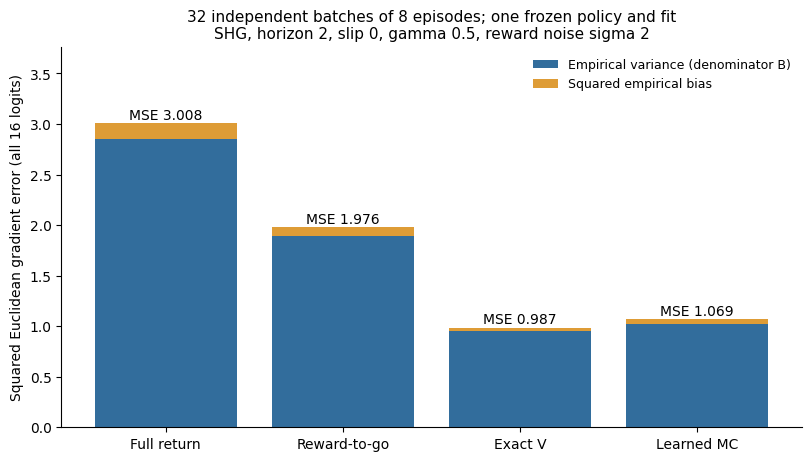

In [31]:
labels = ["Full return", "Reward-to-go", "Exact V", "Learned MC"]
metrics_rows = list(probe_metrics.values())
variance_trace = np.array([m["empirical_variance_trace"] for m in metrics_rows])
bias_squared = np.array([m["squared_empirical_bias"] for m in metrics_rows])
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
x = np.arange(len(labels))
ax.bar(x, variance_trace, color="#326d9c", label="Empirical variance (denominator B)")
ax.bar(x, bias_squared, bottom=variance_trace, color="#de9c36", label="Squared empirical bias")
for i, m in enumerate(metrics_rows):
    ax.text(i, m["mse"] + .04, f"MSE {m['mse']:.3f}", ha="center", fontsize=10)
ax.set_xticks(x, labels)
ax.set_ylim(0, max(m["mse"] for m in metrics_rows)*1.25)
ax.set_ylabel("Squared Euclidean gradient error (all 16 logits)")
ax.set_title("32 independent batches of 8 episodes; one frozen policy and fit\n"
             "SHG, horizon 2, slip 0, gamma 0.5, reward noise sigma 2", fontsize=11)
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

The observed MSEs are **3.0085**, **1.9761**, **0.9865**, and **1.0686** for
full return, reward-to-go, exact V, and the learned baseline respectively.
The stacked bars use variance with denominator B so their heights equal the
empirical MSE exactly. This is one setting with one fitted baseline, not a
universal ranking or a statistically resolved comparison between close bars.

All four estimators have the correct expected gradient in this example, as
established by the earlier exact-expectation calculations and the zero-mean
reward-noise model. Nevertheless, their squared empirical biases here are
**0.1538**, **0.0870**, **0.0384**, and **0.0446**. The estimated noise
contributions to those numbers are **0.0921**, **0.0609**, **0.0306**, and
**0.0330**. These noisy empirical discrepancies do not establish true bias.
The saved coordinatewise standard errors describe uncertainty in each grand
mean, while the scalar trace describes aggregate variation across all logits.

### Reproduce the summary from raw estimates

Serialize and reload the raw run below, then recompute the summary using only
its batch vectors and saved exact gradient. This step performs **no sampling,
fitting, or exact-model evaluation**. Notebook execution keeps the data in
memory; it does not create files. To save it, run from `rl_math`:

```bash
uv sync --locked
uv run --locked python -m gridworld.gradient_probe run --output-dir runs/gradient-probe --device cuda
uv run --locked python -m gridworld.gradient_probe summarize runs/gradient-probe/probe.json
```

The `run` command saves `probe.json` and `summary.json` in a **new** output
directory, refusing to replace existing outputs. Choose a different directory
for a rerun. The summary command needs no GPU and prints the same summary JSON.
To verify equality without collecting another episode:

```bash
uv run --locked python -m gridworld.gradient_probe summarize runs/gradient-probe/probe.json > runs/gradient-probe/recomputed-summary.json
cmp runs/gradient-probe/summary.json runs/gradient-probe/recomputed-summary.json
```

The raw file saves batch estimates rather than every episode gradient; these
are sufficient for all the reported batch metrics and the stacked plot.
Seeds and model/policy/baseline settings also permit recollection in the recorded
software environment. Runtime is observed wall-clock time, not a reproducibility
assertion: totals include setup/collection/fitting/measurement but exclude file
serialization. Generated data under `runs/` stays out of Git.

In [32]:
reloaded_probe = json.loads(json.dumps(probe_run, allow_nan=False))
assert summarize_probe(reloaded_probe) == probe_metrics
print("JSON round trip reproduces every summary value from 32 x 16 batch estimates per estimator.")
print("No new episodes, fit, exact-gradient evaluation, or parameter updates during summary replay.")

JSON round trip reproduces every summary value from 32 x 16 batch estimates per estimator.
No new episodes, fit, exact-gradient evaluation, or parameter updates during summary replay.


## Compare noise and episode count

The preceding pilot measured one setting. Now compare a small, **declared before
collection** sweep of batch sizes $N=(1,8,32)$ and reward-noise standard deviations
$\sigma=(0,2,4)$, using **B=128 independent batches at each of nine settings**.
Each vector is the average of N complete episode gradient sums, including zero
contributions at unvisited rows. All four estimators use the same episodes
within a batch. No policy update is taken.

Keep `SHG`, horizon 2, slip 0, step reward -1, hazard penalty -5, goal bonus 10,
$\gamma=0.5$, and $\pi=(0.1,0.2,0.3,0.4)$ fixed. Fit one MC baseline with the
same 32 training seeds **1000..1031**, at **training sigma=2**, and reuse that
unchanged table at every probe noise level. The exact V baseline also stays fixed:
independent zero-mean reward noise does not change the model expectation.
Changing probe noise therefore does not also change the fitted baseline.

Probes use disjoint seed blocks **10000..25743**, allocated in noise-major then
batch-size order, including distinct seeds across settings. Total collection is
**15,744 shared probe episodes / 31,488 transitions**, plus the one fit's
**32 episodes / 64 transitions**. Equal probe budgets do not imply equal total
data costs. Conclusions about the learned baseline condition on this one fit.

A separate validation pilot used B=8, N=(1,8), sigma=(0,4), and probe seeds
100000..100143; it is excluded from the selected results. The full sweep took
35.78 seconds including analysis and figure writing on the RTX 3090. Timing is
an observation, not a hardware benchmark; validation briefly overlapped the run.

Load the **committed selected summary** below. Viewing or rerunning these cells
does not recollect the sweep or require ignored run files. The command at the end
saves raw vectors and can regenerate this summary and both figures.

In [33]:
from gridworld.monte_carlo_sweep import plot_sweep
from common.gradient_metrics import summarize_comparison

sweep_summary_path = project / "figures/gridworld/monte_carlo/summary.json"
sweep_summary = json.loads(sweep_summary_path.read_text())
assert not sweep_summary["settings"]["pilot"]
assert sweep_summary["settings"]["batch_count"] == 128
assert sweep_summary["settings"]["batch_sizes"] == [1, 8, 32]
assert sweep_summary["settings"]["noise_stds"] == [0., 2., 4.]
print("Settings:", sweep_summary["settings"])
print("Budget:", sweep_summary["budget"])
print("Recorded device:", sweep_summary["device"], sweep_summary["gpu"])
print("Recorded versions:", sweep_summary["versions"])
print("Collection wall-clock seconds:", sweep_summary["runtime_seconds"])
print("Plotted bias coordinate:", sweep_summary["bias_coordinate"])

Settings: {'pilot': False, 'batch_count': 128, 'batch_sizes': [1, 8, 32], 'noise_stds': [0.0, 2.0, 4.0], 'probe_seed_start': 10000, 'training_seeds': [1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012, 1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031], 'training_noise_std': 2.0, 'bootstrap_resamples': 2000, 'bootstrap_seed_start': 20261112}
Budget: {'probe_episodes': 15744, 'probe_transitions': 31488, 'training_episodes': 32, 'training_transitions': 64, 'total_transitions': 31552}
Recorded device: cuda:0 NVIDIA GeForce RTX 3090
Recorded versions: {'python': '3.10.12', 'numpy': '2.2.6', 'torch': '2.14.1+cu130', 'matplotlib': '3.10.9'}
Collection wall-clock seconds: {'collection_and_fit': 0.030660660937428474, 'total_before_analysis': 33.5190586745739}
Plotted bias coordinate: {'index': 5, 'cell': [0, 1], 'remaining': 1, 'action': 'EAST', 'exact_gradient': 0.20000000000000004}


### Put uncertainty on the comparisons

For batch vectors $x_b$ and exact gradient g, retain the preceding definitions:
mean $\bar x$, signed empirical bias $\bar x-g$, sample covariance trace
$s_x^2=\sum_b\|x_b-\bar x\|^2/(B-1)$, and MSE
$\sum_b\|x_b-g\|^2/B$. The squared error of the grand mean is a different
quantity from the average squared error of the individual N-episode estimates.

`summarize_comparison` first calls `summarize_gradients` for each method. Then it
draws B batch indices **with replacement**, keeping each whole vector together.
The same index list is used for all four methods. For example, `[2,0,2]` takes
batch 2 twice and batch 0 once from every method. Recompute signed mean error,
sample covariance trace, and MSE for each of **2,000** such resamples. Their
2.5th and 97.5th percentiles form approximate **pointwise 95% intervals**.
Resampling seeds 20261112..20261120 are recorded in condition order.

For an MSE comparison, subtract reward-to-go's MSE **within each resample**:

$$\Delta=\frac1B\sum_b
\left(\|x_b^{\rm method}-g\|^2-\|x_b^{\rm RTG}-g\|^2\right).$$

This preserves the covariance from using the same episodes. Independently
resampling the methods or individual gradient coordinates would break that
pairing. These are the standard
[paired percentile-bootstrap operations](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html),
implemented directly with NumPy. No new dependency is needed.

The intervals are conditional on the one frozen fit and are not simultaneous
over all coordinates/settings. Coverage is approximate, especially with rare
events or small B; the bootstrap cannot invent events absent from the data.
More resamples sharpen quantiles but do not add observed episodes.

**Do not treat a positive squared empirical bias as proof of true bias.** Its
norm includes sampling noise. We retain it and `mean_noise_floor` as descriptive
points, without a naive percentile interval for squared true bias. Signed
coordinate intervals can straddle zero and show the uncertainty directly.

In [34]:
# A hand-checkable paired comparison, independent of the gridworld.
# Adding a constant second-coordinate error of 1 adds exactly 1 to every
# paired squared error, even though the first-coordinate errors vary widely.
paired_example = summarize_comparison(
    {"base": [[0., 0.], [2., 0.], [4., 0.]],
     "shifted": [[0., 1.], [2., 1.], [4., 1.]]},
    [0., 0.], comparison="base", bootstrap_seed=20261112,
)
for name, row in paired_example["estimators"].items():
    print(name, "MSE:", round(row["metrics"]["mse"], 6),
          "individual MSE interval:", np.round(row["intervals"]["mse"], 6))
paired_difference = paired_example["estimators"]["shifted"]["mse_difference"]
np.testing.assert_allclose(paired_difference["interval"], [1., 1.], atol=1e-14)
print("Paired difference:", round(paired_difference["estimate"], 6),
      "interval:", np.round(paired_difference["interval"], 6))
print("A constant paired difference survives every shared resample.")

base MSE: 6.666667 individual MSE interval: [ 0. 16.]
shifted MSE: 7.666667 individual MSE interval: [ 1. 17.]
Paired difference: 1.0 interval: [1. 1.]
A constant paired difference survives every shared resample.


### Read bias, variance, and MSE separately

**Figure 1.** Columns vary reward noise and the horizontal axis varies the
episode count N. Each point comes from B=128 independent batches. The first row
shows signed mean error for the **predetermined H/1 EAST logit**, whose exact
gradient is +0.2. This coordinate was chosen before inspecting results, following
the worked trajectory above. A zero mean error agrees with the reference.
All coordinate intervals, including unvisited rows, remain in the summary.

The second row shows **sample covariance trace**, with denominator B-1; the third
shows **MSE**, both summed over all 16 logit coordinates. Each row uses the same
vertical scale across noise levels. Variance and MSE are on log scales, so a
factor-of-N change is visible. The sample-variance version of the earlier
decomposition is MSE = squared empirical bias + (B-1)/B times sample variance.
The vertical bars are pointwise bootstrap intervals, not the scatter of the
individual gradient vectors. Methods have small horizontal offsets for clarity.

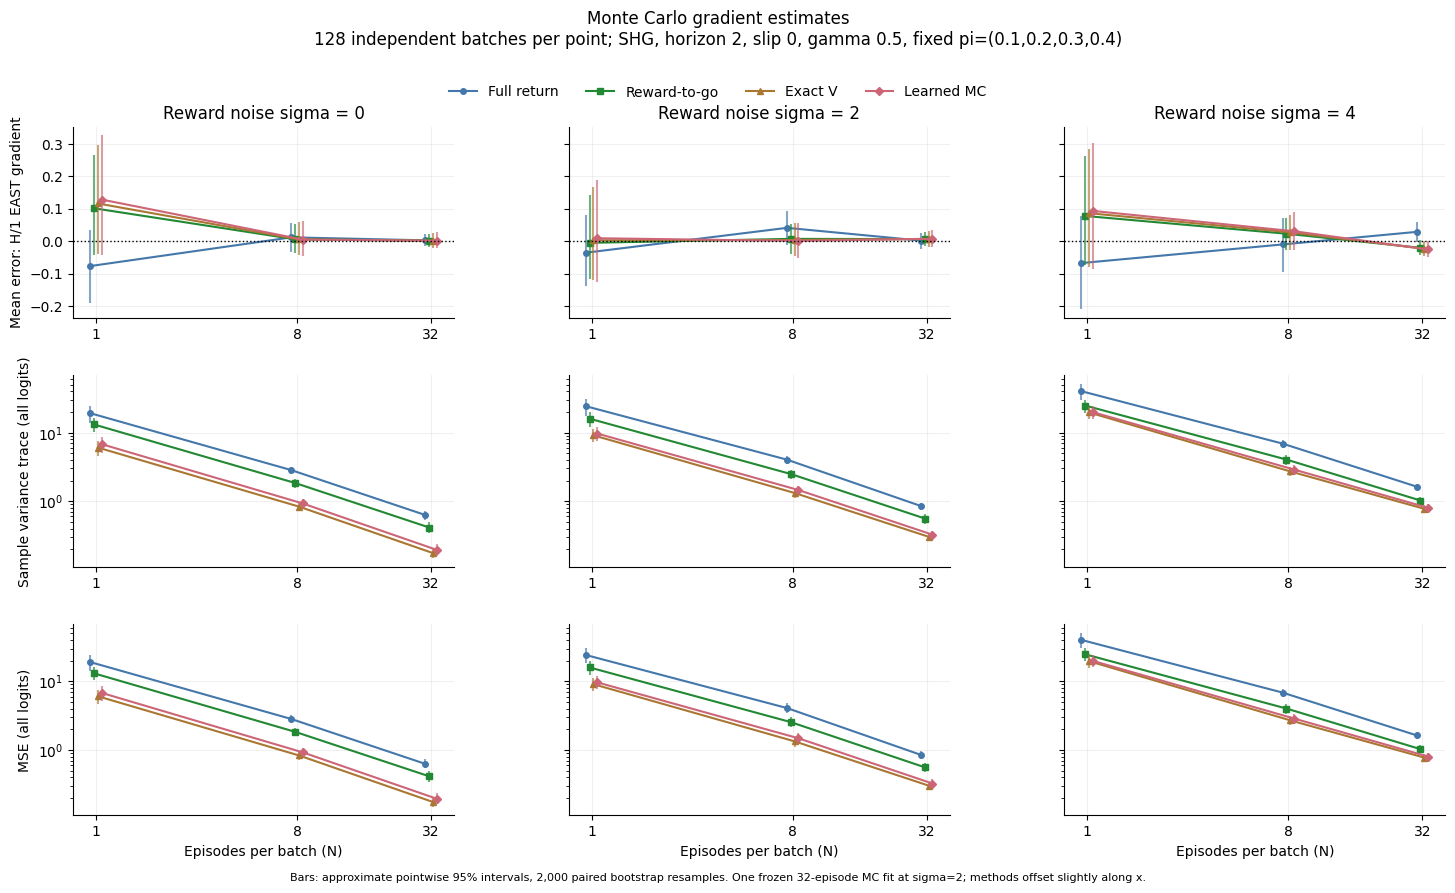

In [35]:
sweep_figures = plot_sweep(sweep_summary)
# Close automatic display handles; explicitly display each saved-data figure
# beside its own caption. No files are written by these cells.
for figure in sweep_figures.values():
    plt.close(figure)
display(sweep_figures["metrics.png"])

### Compare methods on the same episodes

**Figure 2.** Plot the paired difference **method MSE minus reward-to-go MSE**.
A point and interval below zero favor the named method in that setting. Above
zero favors reward-to-go. Overlap between two methods' separate MSE intervals
is not the comparison used here: the paired difference has its own uncertainty.

The table below uses the declared middle setting N=8, sigma=2. It also shows
squared empirical bias and its estimated sampling-noise contribution. Those
two numbers concern the mean of B batches; the MSE column concerns an individual
N-episode batch estimate. Do not add the mean-noise contribution to MSE again.

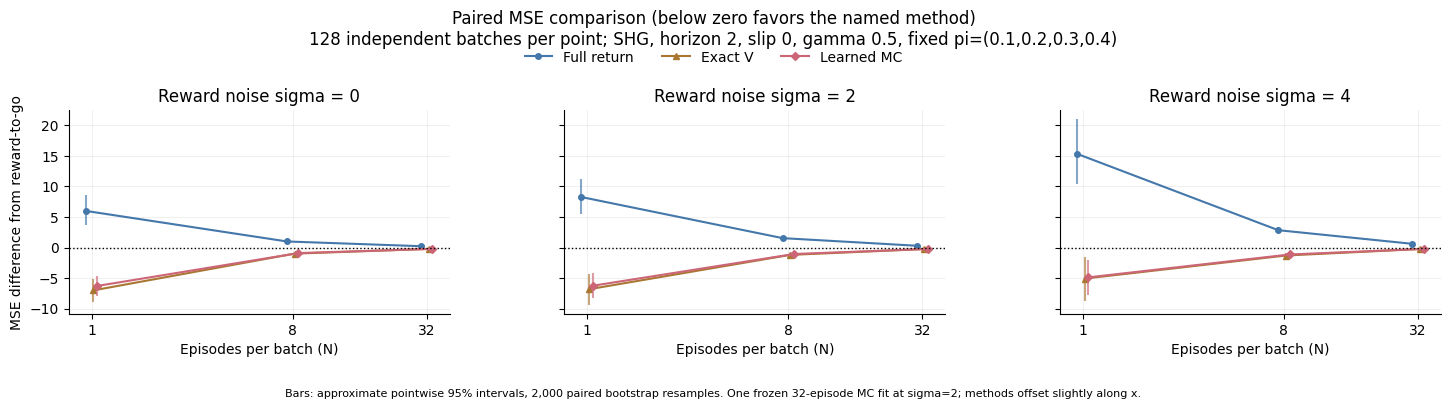

N=8, sigma=2: pointwise 95% paired intervals; B=128
method          MSE [interval]                 delta vs RTG [interval]       bias^2   mean noise
full_return    4.0823 [3.4696 4.7907]   +1.5345 [1.2483 1.8879]   0.0864   0.0315
reward_to_go   2.5477 [2.1325 3.0084]   +0.0000 [0. 0.]   0.0759   0.0195
exact_v        1.3364 [1.1238 1.5639]   -1.2113 [-1.496  -0.9402]   0.0282   0.0103
learned_mc     1.4819 [1.2358 1.7427]   -1.0659 [-1.2982 -0.8457]   0.0366   0.0114


In [36]:
display(sweep_figures["paired_mse.png"])
middle = next(c for c in sweep_summary["conditions"]
              if c["noise_std"] == 2 and c["episodes_per_batch"] == 8)
print("N=8, sigma=2: pointwise 95% paired intervals; B=128")
print("method          MSE [interval]                 delta vs RTG [interval]       bias^2   mean noise")
for name, row in middle["comparison"]["estimators"].items():
    m, delta = row["metrics"], row["mse_difference"]
    print(f"{name:14s} {m['mse']:.4f} {np.round(row['intervals']['mse'], 4)} "
          f"  {delta['estimate']:+.4f} {np.round(delta['interval'], 4)} "
          f"  {m['squared_empirical_bias']:.4f}   {m['mean_noise_floor']:.4f}")

Larger N reduces variance and MSE approximately with **1/N**, as expected when
averaging independent episode sums. Stronger reward noise increases both. At
N=8, increasing sigma from 0 to 4 raises full-return MSE from **2.826 to 6.854**,
and exact-baseline MSE from **0.833 to 2.704**. A baseline does not remove all noise.

At all nine settings, the paired intervals put full return above reward-to-go,
and both baseline methods below reward-to-go. For example, at N=8, sigma=2,
exact V minus RTG is **-1.211**, with pointwise interval **[-1.496, -0.940]**.
Learned MC minus RTG is **-1.066**, with interval **[-1.298, -0.846]**.
These are measurements for this policy, reward model, and single fit. They do
not establish a universal ranking. In particular, close exact-V and learned-MC
curves do not establish a difference between those two methods from overlapping
individual intervals; the plotted paired comparisons use RTG as the reference.

All displayed H/1 EAST signed-bias intervals contain zero. That is consistent
with the earlier exact-expectation checks, but is not a proof of unbiasedness
or a simultaneous statement about all coordinates. Unbiasedness follows from
the estimator identities under the fixed-policy, independent-data assumptions.
The baseline was fitted once at sigma=2; variation over independent baseline
fits and different policies is outside this sweep.

### Which noise is removed, and which remains?

**Reward-to-go removes past rewards from a later action's learning signal.**
The later action cannot affect those rewards, and its conditional expected
score is zero. **A baseline subtracts the expected state-dependent return.**
It can reduce variation from whether a sampled trajectory does better or worse
than usual, but cannot predict a fresh independent reward-noise draw. Random
actions and resulting paths remain even at sigma=0. This sweep has no transition
slip, so it isolates action and reward sampling.

There is a small quantitative check specific to our two-step example. Write
$z_t=\nabla\log\pi(a_t\mid s_t)$ as a vector in all 16 logit coordinates, and
let $\epsilon_1,\epsilon_2$ be independent zero-mean reward noises of variance
$\sigma^2$. The noise-dependent parts of the episode gradients are:

$$g_{\rm full,noise}=(\epsilon_1+\gamma\epsilon_2)(z_0+z_1),$$
$$g_{\rm RTG,noise}=\epsilon_1z_0+\gamma\epsilon_2(z_0+z_1).$$

The removed term is $\epsilon_1z_1$: the first reward's noise was assigned to
the second action by full return. Both baseline variants have the same
noise-dependent term as plain RTG, because the fixed baseline does not depend
on these probe noises.

Different remaining times have different parameter rows, so $z_0^Tz_1=0$ here.
For the softmax row with probabilities $(.1,.2,.3,.4)$,
$\mathbb E[\|z_t\|^2]=1-\sum_a\pi(a)^2=0.7$. Thus the **additional covariance
trace caused by independent reward noise**, averaged over paths, is:

$$\Delta v_{\rm full}=\sigma^2(1+\gamma^2)(0.7+0.7)=1.75\sigma^2,$$
$$\Delta v_{\rm RTG}=\sigma^2\left[0.7+\gamma^2(0.7+0.7)\right]=1.05\sigma^2.$$

For an N-episode average, divide these contributions by N. They are additional
to variance at sigma=0, which can differ between the baseline methods. These
coefficients rely on this horizon, policy, and separate time-specific rows;
they are not general variance formulas. Empirical differences across independently
sampled settings need not equal these population contributions exactly.

In [37]:
probabilities = np.array([.1, .2, .3, .4])
score_vectors = np.eye(4) - probabilities
expected_score_norm = np.dot(probabilities, np.square(score_vectors).sum(axis=1))
discount = sweep_summary["objective"]["gamma"]
full_noise_coefficient = (1 + discount**2) * 2 * expected_score_norm
rtg_noise_coefficient = expected_score_norm + discount**2 * 2 * expected_score_norm
np.testing.assert_allclose([expected_score_norm, full_noise_coefficient, rtg_noise_coefficient],
                           [.7, 1.75, 1.05])
print("Expected squared score norm:", round(expected_score_norm, 2))
print("Added variance trace: full = 1.75*sigma^2/N; all RTG variants = 1.05*sigma^2/N")
print("For N=8, sigma=4: full adds", round(full_noise_coefficient * 4**2 / 8, 2),
      "; RTG/exact V/learned MC each add", round(rtg_noise_coefficient * 4**2 / 8, 2))

Expected squared score norm: 0.7
Added variance trace: full = 1.75*sigma^2/N; all RTG variants = 1.05*sigma^2/N
For N=8, sigma=4: full adds 3.5 ; RTG/exact V/learned MC each add 2.1


### Recollect or rebuild the figures

The reusable runner is `gridworld.monte_carlo_sweep`. From `rl_math`, use new
output-directory names for each run:

```bash
uv sync --locked
uv run --locked python -m gridworld.monte_carlo_sweep run --pilot --output-dir runs/mc-pilot --device cuda
uv run --locked python -m gridworld.monte_carlo_sweep run --output-dir runs/mc-sweep --device cuda
uv run --locked python -m gridworld.monte_carlo_sweep report runs/mc-sweep/sweep.json --output-dir runs/mc-replot
cmp runs/mc-sweep/summary.json runs/mc-replot/summary.json
cmp runs/mc-sweep/metrics.png runs/mc-replot/metrics.png
cmp runs/mc-sweep/paired_mse.png runs/mc-replot/paired_mse.png
```

`run` writes **sweep.json** with every batch vector, exact reference, coordinate
order, episode seeds, baseline values/counts, settings, versions, device, and
runtime, plus **summary.json** and both figures. `report` resamples the saved
vectors using recorded bootstrap seeds and regenerates the summary and figures
without sampling episodes, fitting a baseline, evaluating the exact model, or
using a GPU. `--device cpu` is available for reference collection. Each output
directory must be new; existing results are preserved.

The selected files are under `figures/gridworld/monte_carlo/`; raw run data stays
under ignored `runs/`. The committed summary supports viewing every result and
replotting, while the raw vectors support recomputing all statistics and
intervals. This sweep compares Monte Carlo methods; TD is introduced next.

## One-step TD: predict the remaining return

Monte Carlo waits for the episode to finish and adds up its remaining rewards.
One-step **temporal difference (TD)** uses the next observed reward, then asks a
fixed critic to predict everything after it. A critic is just a function that
predicts the return from a state; here it is a small state/time table.

| Method | Estimate of the return starting now | Subtract now |
|---|---|---|
| Monte Carlo baseline | Actual remaining return $G_t$ | $\widehat V(s_t)$ |
| One-step TD | $r_{t+1}+\gamma\widehat V(s_{t+1})$ | $\widehat V(s_t)$ |

Using a value prediction inside the return target is called **bootstrapping**.
The one-step TD advantage estimate is

$$\delta_t=r_{t+1}+\gamma(1-d_t)\widehat V(s_{t+1})-\widehat V(s_t),$$

where $d_t$ is true at a genuine task ending. The actor uses
$\sum_t\gamma^t\delta_t\nabla_\theta\log\pi_\theta(a_t\mid s_t)$, averaged
over whole episodes. The inner discount moves the future value back one step;
the outer $\gamma^t$ moves this action's contribution back to episode start.

`one_step_td_advantages` computes the detached residuals.
`one_step_td_gradient` applies the outer discounts and differentiates only the
log-probabilities. Both current and next value predictions are held constant,
even when their inputs carry an autograd graph. There are no actor or critic updates.

### Work through S -> H -> G

Keep the same two-step `SHG` task, no slip, $\gamma=0.5$, and action probabilities
$(0.1,0.2,0.3,0.4)$ for NORTH/EAST/SOUTH/WEST. Use model-mean rewards here.
With one step left, $V(S,1)=-2$ and $V(H,1)=-1$. At the start, EAST has
$Q=-6+0.5(-1)=-6.5$; the other actions have $Q=-1+0.5(-2)=-2$.
Thus $V(S,2)=0.2(-6.5)+0.8(-2)=-2.9$.

For the EAST, EAST path, the observed rewards are $-6$ and $9$:

| Transition | Exact-critic TD residual | Actor weight $\gamma^t\delta_t$ |
|---|---|---|
| S/2 -> H/1 | $-6+0.5(-1)-(-2.9)=-3.6$ | $-3.6$ |
| H/1 -> terminal goal | $9+0-(-1)=10$ | $0.5(10)=5$ |

Monte Carlo instead gives weights $(G_0-V(S,2),\,0.5(G_1-V(H,1)))=(1.4,5)$
on this path, because $G_0=-6+0.5(9)=-1.5$. TD does not give the first action
credit for this particular lucky future EAST action: it uses the expected future
return $-1$. The two methods can agree in expectation while differing on one path.

Now deliberately overestimate **only H with one step left** by 4:
$\widehat V(H,1)=3$, exact everywhere else. The TD residuals become $(-1.6,6)$,
and the actor weights become $(-1.6,3)$. This is a controlled table error,
not a critic trained on probe episodes.

The code deliberately supplies 999 as the terminal prediction to check that
it is ignored. Reaching the goal or exhausting this task's defined horizon
means no future reward. An external rollout cutoff would keep the bootstrap
from its final observation; this complete-episode probe has no such cutoffs.

In [38]:
from algorithms.advantages import one_step_td_advantages
from algorithms.actor_critic import one_step_td_gradient

td_gamma = .5
td_reference = differentiate_policy(tiny, tiny_policy, td_gamma)
td_exact = {s: v.detach().clone() for s, v in td_reference.values.v.items()}
td_imperfect = {s: v.clone() for s, v in td_exact.items()}
td_imperfect[State((0, 1), 1)] += 4.
td_tables = {"exact": td_exact, "imperfect": td_imperfect}
td_states = [tiny.start_state, State((0, 1), 1)]
td_parameters = tuple(tiny_policy.logits.values())
for label, table in td_tables.items():
    current = torch.stack([table[s] for s in td_states])
    future = torch.stack([table[td_states[1]], current.new_tensor(999.)])
    delta = one_step_td_advantages([-6., 9.], current, future, [False, True], td_gamma)
    weights = delta * delta.new_tensor([1., .5])
    gradient = dict(zip(tiny_policy.logits, one_step_td_gradient(
        torch.stack([tiny_policy.log_probabilities(s)[1] for s in td_states]),
        [-6., 9.], td_parameters, td_gamma,
        values=current, next_values=future, terminated=[False, True],
    )))
    expected = [-3.6, 10.] if label == "exact" else [-1.6, 6.]
    torch.testing.assert_close(delta, delta.new_tensor(expected), rtol=1e-12, atol=1e-14)
    print(label, "delta:", delta.cpu().numpy().round(3), "actor weights:", weights.cpu().numpy().round(3))
    for state, weight in zip(td_states, weights):
        row = gradient[state]
        torch.testing.assert_close(row, weight * row.new_tensor([-.1, .8, -.3, -.4]),
                                   rtol=1e-12, atol=1e-14)
        print(f"  {state.cell}/{state.remaining} gradient:", row.cpu().numpy().round(3))

exact delta: [-3.6 10. ] actor weights: [-3.6  5. ]
  (0, 0)/2 gradient: [ 0.36 -2.88  1.08  1.44]
  (0, 1)/1 gradient: [-0.5  4.  -1.5 -2. ]
imperfect delta: [-1.6  6. ] actor weights: [-1.6  3. ]
  (0, 0)/2 gradient: [ 0.16 -1.28  0.48  0.64]
  (0, 1)/1 gradient: [-0.3  2.4 -0.9 -1.2]


### Why exact TD is unbiased, and how we can check it exactly

If the critic is the true value function, the Bellman equation gives

$$\mathbb E[\delta_t\mid s_t=s,a_t=a]
=Q^\pi(s,a)-V^\pi(s)=A^\pi(s,a).$$

So the conditional mean of the TD target is the same advantage used in the
policy-gradient theorem. Multiplying by the action score and the outer discount,
then averaging, gives the exact gradient. The same statement holds with this
sampler's independent zero-mean reward noise. The residual itself can still be noisy.

We can compute an **exact reference gradient** because this tiny model tells us
every transition probability and mean reward. `evaluate_policy` averages over
all next states and actions, working backward from zero terminal values. It
expresses the expected start return as a differentiable function of the policy
logits. `differentiate_policy` differentiates that function with PyTorch; it
does not estimate the gradient from sampled episodes. Here $J=-2.9$.

As a separate check, reuse all **16 possible two-action paths**. Compute each
path's estimator, multiply by its exact probability, and sum. Compare four
methods: MC with exact V, MC with the imperfect table, TD with exact V, and TD
with the imperfect table. This gives the expected estimator without sampling
error. Model-mean rewards suffice because the estimators are linear in the
independent zero-mean reward noise. Tests also enumerate slipping transitions
and early goal endings, and check $\gamma=0$ and 1.

The two uses of autograd differ: the **reference** differentiates the complete
Bellman calculation, including future policy choices; the **sampled estimator**
holds its targets fixed and differentiates just the selected action log-probabilities.

In [39]:
td_reference_rows = torch.stack([td_reference.gradient[s] for s in tiny_policy.logits])
td_expected = {}
for method in ("MC", "TD"):
    for label, table in td_tables.items():
        expected = torch.zeros_like(td_reference_rows)
        for probability, path_states, action_indices, path_rewards in exact_paths:
            logp = torch.stack([tiny_policy.log_probabilities(s)[a]
                               for s, a in zip(path_states, action_indices)])
            current = torch.stack([table[s] for s in path_states])
            if method == "MC":
                gradient = reward_to_go_gradient(logp, path_rewards, td_parameters, td_gamma,
                                                 baselines=current)
            else:
                outcomes = [tiny.transitions(s, tuple(Action)[a])[0]
                            for s, a in zip(path_states, action_indices)]
                gradient = one_step_td_gradient(
                    logp, path_rewards, td_parameters, td_gamma, values=current,
                    next_values=torch.stack([table[o.next_state] for o in outcomes]),
                    terminated=[tiny.is_terminal(o.next_state) for o in outcomes],
                )
            expected += probability * torch.stack(gradient)
        td_expected[f"{method} {label}"] = expected
        if method == "MC" or label == "exact":
            torch.testing.assert_close(expected, td_reference_rows, rtol=1e-12, atol=1e-14)
        print(f"{method} {label:9s} max |expected - exact| = "
              f"{(expected - td_reference_rows).abs().max().item():.6f}")

MC exact     max |expected - exact| = 0.000000
MC imperfect max |expected - exact| = 0.000000
TD exact     max |expected - exact| = 0.000000
TD imperfect max |expected - exact| = 0.320000


### Where the +0.32 bias comes from

Let $e(s)=\widehat V(s)-V^\pi(s)$ be the fixed critic error. Replacing exact V
changes the TD residual by $\gamma(1-d_t)e(s_{t+1})-e(s_t)$.
The current-state term $-e(s_t)$ cancels in the expected gradient: it is the
same number for every action at that state, and the action scores average to zero.
The next-state error can depend on which action was taken, so it need not cancel:

$$\operatorname{Bias}(\widehat g_{\rm TD})
=\mathbb E\!\left[\sum_t\gamma^{t+1}(1-d_t)e(s_{t+1})
\nabla_\theta\log\pi_\theta(a_t\mid s_t)\right].$$

Here only the first action EAST leads to the erroneous H/1 prediction:

1. The extra future-value target is $\gamma e(H,1)=0.5\times4=2$.
2. EAST is selected with probability 0.2.
3. Its score for the four S/2 logits is $(-0.1,0.8,-0.3,-0.4)$.
4. The expected extra gradient is therefore
   $2\times0.2\times(-0.1,0.8,-0.3,-0.4)=(-0.04,0.32,-0.12,-0.16)$.

Thus the S/2 EAST gradient changes from **-0.72 to -0.40**. The critic makes
entering the hazard look less bad. At H/1, the same error is only a current-state
subtraction, so it cancels in expectation. All other gradient coordinates have
zero bias. The total squared bias is
$(-0.04)^2+0.32^2+(-0.12)^2+(-0.16)^2=0.144$.

Using this table only as a **Monte Carlo baseline** introduces no next-state
prediction, so only the canceling term remains. This differs from fitting a
baseline on the probe's own returns: there is no such data reuse here. The TD
bias comes from replacing the future return with an imperfect prediction.
Detaching targets prevents an unwanted derivative; it cannot fix that prediction.

In [40]:
td_start_row = list(tiny_policy.logits).index(tiny.start_state)
td_true_bias = torch.zeros_like(td_reference_rows)
td_true_bias[td_start_row] = td_true_bias.new_tensor([-.04, .32, -.12, -.16])
torch.testing.assert_close(td_expected["TD imperfect"] - td_reference_rows, td_true_bias,
                           rtol=1e-12, atol=1e-14)
assert np.isclose(td_true_bias.square().sum().item(), .144)
print("Exact S/2 gradient:       ", td_reference_rows[td_start_row].cpu().numpy().round(4))
print("Expected imperfect TD:   ", td_expected["TD imperfect"][td_start_row].cpu().numpy().round(4))
print("True bias:               ", td_true_bias[td_start_row].cpu().numpy().round(4))
print("True squared bias (all coordinates):", round(td_true_bias.square().sum().item(), 6))

Exact S/2 gradient:        [ 0.09 -0.72  0.27  0.36]
Expected imperfect TD:    [ 0.05 -0.4   0.15  0.2 ]
True bias:                [-0.04  0.32 -0.12 -0.16]
True squared bias (all coordinates): 0.144


### Measure the same short frozen-policy probe

`run_short_probe(include_td=True)` adds three methods to the original four:
exact TD, imperfect TD, and the same imperfect table used as a Monte Carlo
baseline. Every method uses the same **32 batches of 8 episodes**, seeds 0..255,
$\gamma=0.5$, reward noise $\sigma=2$, and frozen `SHG` policy. Each batch is the
mean of whole episode gradient sums, keeping zeros in unvisited logit rows.

This reconstructs the earlier 256 probes, not a second independent dataset.
The first four methods retain their original raw estimates. The learned MC
baseline still uses seeds 1000..1031, a separate 32-episode/64-transition fit.
The deliberately perturbed critic uses no fitting data. All seven methods
share the 512 probe transitions; exact model calculations have no sampled
transition cost. Each table stays fixed throughout the probe.

The raw JSON includes current-state critic predictions in the saved policy-row
order, the +4 construction, zero terminal bootstrap, exact gradient, batch
vectors, seeds, device, software versions, and elapsed time. The notebook keeps
these in memory; the command at the end saves them.

In [41]:
td_run = run_short_probe(device="cuda", include_td=True)
td_metrics = summarize_probe(td_run)
for name in probe_run["batch_estimates"]:
    np.testing.assert_allclose(td_run["batch_estimates"][name], probe_run["batch_estimates"][name],
                               rtol=1e-12, atol=1e-13)
assert sum(td_run["sampling"]["transitions_per_batch"]) == 512
assert td_run["critics"]["td_imperfect"]["training_transitions"] == 0
np.testing.assert_allclose(td_run["critics"]["td_imperfect"]["values"],
                           [td_imperfect[s].item() for s in tiny_policy.logits], atol=1e-14)
td_coordinate = 4 * td_start_row + 1  # S/2, EAST, in the saved row/action order.
print("method          S/2 EAST empirical bias  mean SE    bias^2  variance(B)       MSE")
for name, m in td_metrics.items():
    print(f"{name:14s} {m['empirical_bias'][td_coordinate]:+18.6f} "
          f"{m['mean_standard_error'][td_coordinate]:9.6f} {m['squared_empirical_bias']:9.6f} "
          f"{m['empirical_variance_trace']:12.6f} {m['mse']:9.6f}")
print("Device:", td_run["device"], td_run["gpu"], "versions:", td_run["versions"])
print("Seconds:", {k: round(v, 3) for k, v in td_run["runtime_seconds"].items()})
assert summarize_probe(json.loads(json.dumps(td_run))) == td_metrics

method          S/2 EAST empirical bias  mean SE    bias^2  variance(B)       MSE
full_return             +0.176355  0.138539  0.153816     2.854661  3.008477
reward_to_go            +0.176355  0.138539  0.086960     1.889098  1.976059
exact_v                 +0.072136  0.093294  0.038381     0.948121  0.986502
learned_mc              +0.097826  0.103568  0.044579     1.024022  1.068601
imperfect_v             +0.072136  0.093294  0.037426     0.980600  1.018026
td_exact                +0.063310  0.075206  0.038916     0.786861  0.825777
td_imperfect            +0.325810  0.053427  0.186738     0.701480  0.888218
Device: cuda:0 NVIDIA GeForce RTX 3090 versions: {'python': '3.10.12', 'numpy': '2.2.6', 'torch': '2.14.1+cu130'}
Seconds: {'measurement': 1.112, 'baseline_collection_and_fit': 0.018, 'total_before_serialization': 1.135}


The exact TD estimator's S/2 EAST **empirical** bias is about +0.063, with a
mean standard error of 0.075. Its **true** bias is zero, as enumeration proved.
Imperfect TD's empirical bias is about +0.326, close to its known true bias +0.32.
The bars below show **two standard errors of the mean**, not bootstrap intervals
or a formal multiple-comparison test. The hollow diamonds show exact expectations.

Across all 16 logits, measured MSE is about **0.826** for exact TD, **0.888** for
imperfect TD, **0.987** for exact-baseline MC, and **1.018** for imperfect-baseline
MC. These are descriptive results for one short probe. Even the biased estimator
can have lower MSE than an unbiased one at this batch size if its variance is
smaller. More independent episodes per batch reduce variance, but cannot remove
this fixed TD bias: its population MSE approaches the squared bias **0.144**.
The unbiased methods' population MSE approaches zero under these fixed-table
assumptions. No universal variance ranking follows from these measurements.

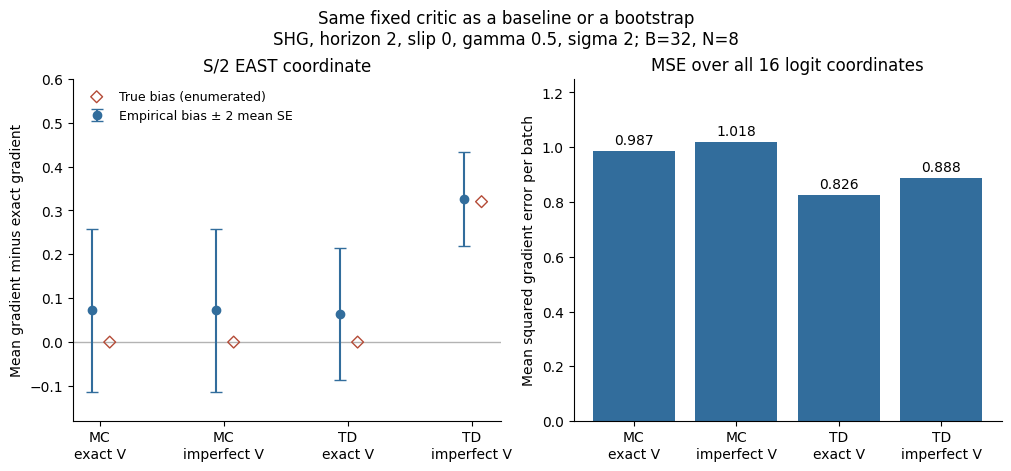

In [42]:
td_names = ["exact_v", "imperfect_v", "td_exact", "td_imperfect"]
td_labels = ["MC\nexact V", "MC\nimperfect V", "TD\nexact V", "TD\nimperfect V"]
td_x = np.arange(len(td_names))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), layout="constrained")
axes[0].axhline(0., color="0.7", lw=1)
axes[0].errorbar(td_x - .06, [td_metrics[n]["empirical_bias"][td_coordinate] for n in td_names],
                 yerr=[2*td_metrics[n]["mean_standard_error"][td_coordinate] for n in td_names],
                 fmt="o", capsize=4, color="#326d9c", label="Empirical bias ± 2 mean SE")
axes[0].scatter(td_x + .08, [0., 0., 0., .32], marker="D", facecolors="none",
                edgecolors="#b44b37", label="True bias (enumerated)", zorder=3)
axes[0].set_ylabel("Mean gradient minus exact gradient")
axes[0].set_title("S/2 EAST coordinate")
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
axes[0].set_ylim(-.18, .60)
axes[1].bar(td_x, [td_metrics[n]["mse"] for n in td_names], color="#326d9c")
for i, name in enumerate(td_names):
    axes[1].text(i, td_metrics[name]["mse"] + .025, f"{td_metrics[name]['mse']:.3f}", ha="center")
axes[1].set_title("MSE over all 16 logit coordinates")
axes[1].set_ylabel("Mean squared gradient error per batch")
axes[1].set_ylim(0., 1.25)
for ax in axes:
    ax.set_xticks(td_x, td_labels)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Same fixed critic as a baseline or a bootstrap\n"
             "SHG, horizon 2, slip 0, gamma 0.5, sigma 2; B=32, N=8", fontsize=12)
display(fig)
plt.close(fig)

### Save and replay the TD probe

From `rl_math`, run the following with a new output directory:

```bash
uv sync --locked
uv run --locked python -m gridworld.gradient_probe run --td --output-dir runs/td-probe --device cuda
uv run --locked python -m gridworld.gradient_probe summarize runs/td-probe/probe.json > runs/td-probe/recomputed-summary.json
cmp runs/td-probe/summary.json runs/td-probe/recomputed-summary.json
```

`run` saves the raw vectors and settings in `probe.json` and all seven methods'
metrics in `summary.json`. `summarize` reads only the saved raw data and needs
no GPU, resampling, fitting, or exact-model evaluation. `--device cpu` provides
a reference collection. Omitting `--td` keeps the original four Monte Carlo
methods. Existing output directories are refused, so choose a new name for a rerun.

The shared estimator code is in `algorithms/advantages.py` and
`algorithms/actor_critic.py`; the game-specific pairing and settings are in
`gridworld/gradient_probe.py`. This step studies one-step TD with fixed tables.
Critic training, n-step returns, and GAE belong to later steps.